In [1]:
import numpy as np
import numpy.random as npr
import scipy.sparse as sp
import networkx as nx
import networkx.algorithms.bipartite as bpt
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import rsmf # right-size my figure, could be helpful for the paper

In [2]:
# Configure Matplotlib fonts to match IEEE template
plt.rcParams['font.family'] = 'serif'  # Set the main font family to serif
plt.rcParams['font.monospace'] = ['Courier']  # Use Courier for monospaced text
plt.rcParams['font.serif'] = ['Computer Modern', 'DejaVu Serif', 'Liberation Serif', 'Nimbus Roman']
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Liberation Sans', 'Nimbus Sans']
plt.rc('text', usetex=True)

# Benchmarking Peeling+Guessing on the optimized PEG codes

- HGP codes where the classical code was generated with PEG, and later optimized via Simulated Annealing for performance on the quantum erasure channel

In [3]:
import h5py

results = {}
with h5py.File("peeling_guessing_HGP_benchmark.hdf5", "r") as f: 
    for code, grp in f.items():
        print(code)
        print(grp.keys())
        print(grp.attrs.keys())
        results[code] = {"ML_ler": np.concatenate([subgrp["ML_ler"][()] for subgrp in grp.values()]), 
                         "ML_eb": np.concatenate([subgrp["ML_eb"][()] for subgrp in grp.values()]), 
                         "N": grp.attrs["N"], "K": grp.attrs["K"], "D": grp.attrs["D"],
                         "n": grp.attrs["n"], "k": grp.attrs["k"], "d": grp.attrs["d"], "s": grp.attrs["s"],
                         "nt": grp.attrs["nt"], "kt": grp.attrs["kt"], "dt": grp.attrs["dt"], "st": grp.attrs["st"],
                        }
        for d in [0, 1]:
            results[code][f"avgSS_branch_d={d}"] = np.stack([subgrp[f"avgSS_branch_d={d}"][()] for subgrp in grp.values()])
            for g in range(7):
                results[code][f'branching_d{d}_g{g}_ler'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_ler'][()] for subgrp in grp.values()])
                results[code][f'branching_d{d}_g{g}_eb'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_eb'][()] for subgrp in grp.values()])
                results[code][f"minSS_branch_d={d}_g={g}"] = grp.attrs[f"minSS_branch_d={d}_g={g}"]
                
        reordering = [int(lbl.split('ER=')[1]) for lbl in grp.keys()]
        results[code]['ML_ler'][reordering] = np.concatenate([subgrp["ML_ler"][()] for subgrp in grp.values()])
        results[code]['ML_eb'][reordering] = np.concatenate([subgrp["ML_eb"][()] for subgrp in grp.values()])
        for d in [0, 1]:
            results[code][f"avgSS_branch_d={d}"][reordering] = np.stack([subgrp[f"avgSS_branch_d={d}"][()] for subgrp in grp.values()])
            for g in range(7):
                results[code][f'branching_d{d}_g{g}_ler'][reordering] = np.concatenate([subgrp[f"branching_d{d}_g{g}_ler"][()] for subgrp in grp.values()])
                results[code][f'branching_d{d}_g{g}_eb'][reordering] = np.concatenate([subgrp[f"branching_d{d}_g{g}_eb"][()] for subgrp in grp.values()])
        
        safe_div = np.vectorize(lambda a,b: a/b if b > 0 else 0)
        print(safe_div(results[code]['ML_eb'], results[code]['ML_eb']))


[20,5,8]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['D', 'K', 'N', 'd', 'dt', 'k', 'kt', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_branch_d=1_g=2', 'minSS_branch_d=1_g=3', 'minSS_branch_d=1_g=4', 'minSS_branch_d=1_g=5', 'minSS_branch_d=1_g=6', 'n', 'nt', 's', 'st']>
[0 1 1 1 1 1 1 1 1 1]
[28,7,10]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['D', 'K', 'N', 'd', 'dt', 'k', 'kt', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_branch_d=1_g=2', 'minSS_branch_d=1_g=3', 'minSS_branch_d=1_g=4', 'minSS_branch_d=

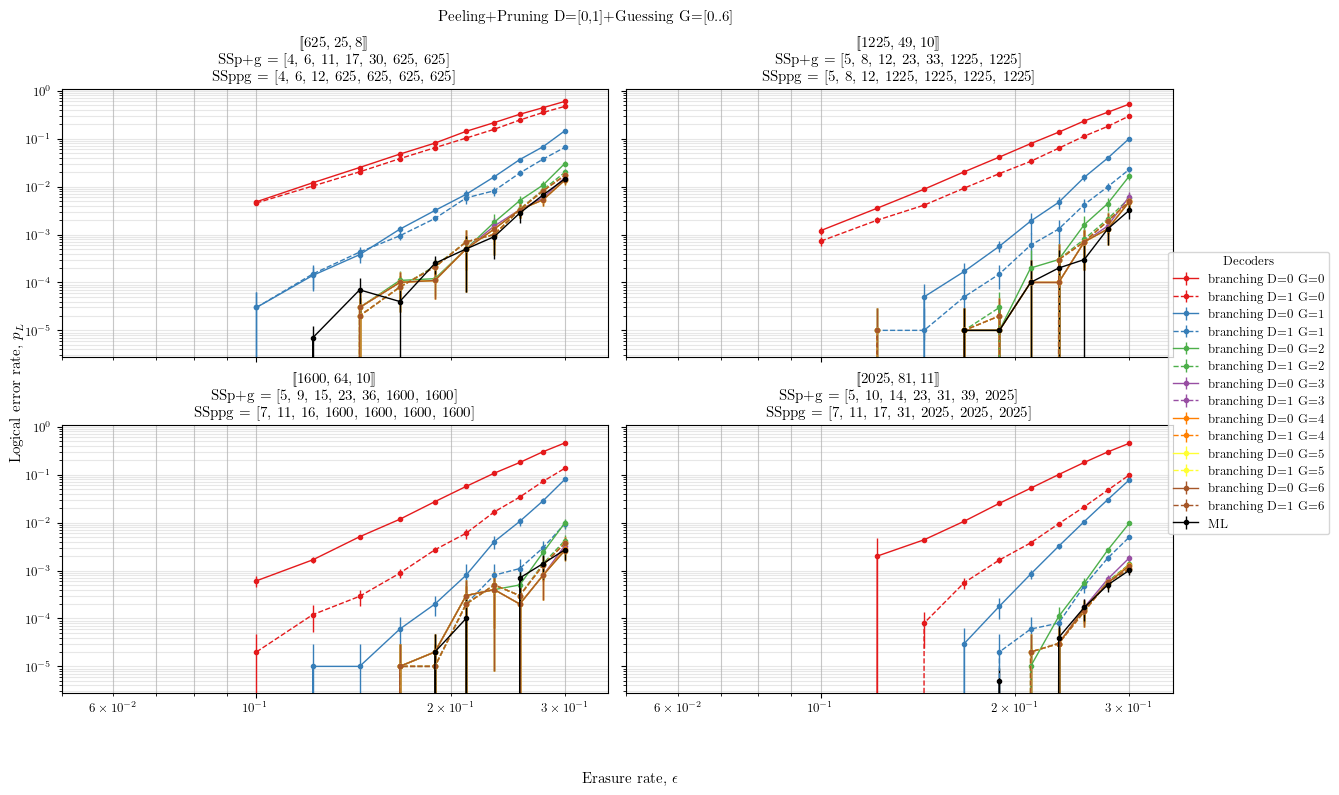

In [4]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=9)


fig, axs = plt.subplots(2, 2, figsize=(12,8), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']

er = np.linspace(0.10, 0.30, 10)

codes = sorted(results.keys(), key=lambda x: results[x]["K"])

handles, labels = None, None

for code, ax in zip(codes, axs.flatten()):
    data_dict = results[code]
    ax.set_title(r'$[\!['+f'{data_dict["N"]}, {data_dict["K"]}, {data_dict["D"]}'+r']\!]$' \
                +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    
    for g in range(7):
        ax.errorbar(x=er, y=data_dict[f'branching_d{0}_g{g}_ler'], yerr=data_dict[f'branching_d{0}_g{g}_eb'], 
                    fmt='.-', label=f'branching D={0} G={g}', linewidth=1, color=cmap(g))
        ax.errorbar(x=er, y=data_dict[f'branching_d{1}_g{g}_ler'], yerr=data_dict[f'branching_d{1}_g{g}_eb'], 
                    fmt='.', label=f'branching D={1} G={g}', linewidth=1, linestyle='--', color=cmap(g))
    ax.errorbar(x=er, y=data_dict['ML_ler'], yerr=data_dict['ML_eb'], fmt='.-', label='ML', linewidth=1, color='k')

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

    ax.set_xlim([0.05, 0.35])
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.98, 0.5), ncol=1, title='Decoders')

plt.suptitle(f'Peeling+Pruning D=[0,1]+Guessing G=[0..6]')
plt.tight_layout()
plt.subplots_adjust(bottom=0.125)
# plt.savefig(f'../img/ppg_hgp_plots.pdf')

plt.show()

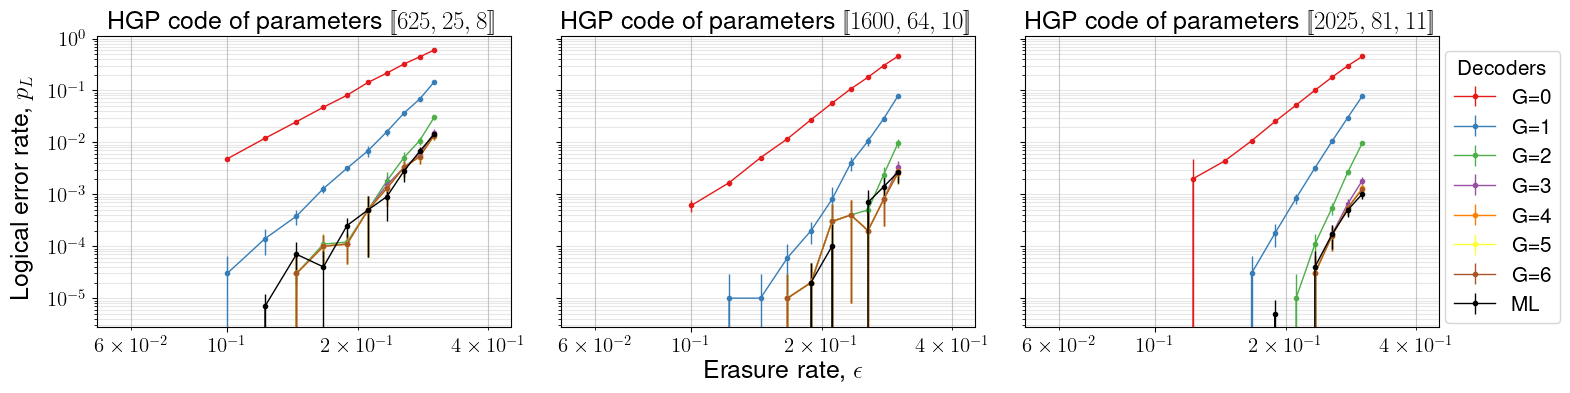

In [5]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
# rc('font', family='serif', size=15)

# Match Beamer’s default font (sans-serif)
rc('font', family='sans-serif', size=15)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Latin Modern Sans', 'Helvetica', 'DejaVu Sans']

# Ensure math text matches LaTeX
rc('mathtext', fontset='cm')  # use Computer Modern for math


fig, axs = plt.subplots(1, 3, figsize=(15,4), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']

er = np.linspace(0.10, 0.30, 10)

# codes = sorted(results.keys(), key=lambda x: results[x]["K"])
codes = ['[20,5,8]', '[32,8,10]', '[36,9,11]']


handles, labels = None, None

for code, ax in zip(codes, axs.flatten()):
    data_dict = results[code]
    ax.set_title(r'HGP code of parameters $[\!['+f'{data_dict["N"]}, {data_dict["K"]}, {data_dict["D"]}'+r']\!]$')# \
                # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    
    for g in range(7):
        ax.errorbar(x=er, y=data_dict[f'branching_d{0}_g{g}_ler'], yerr=data_dict[f'branching_d{0}_g{g}_eb'], 
                    fmt='.-', label=f'G={g}', linewidth=1, color=cmap(g))
        # ax.errorbar(x=er, y=data_dict[f'branching_d{0}_g{g}_ler'], yerr=data_dict[f'branching_d{0}_g{g}_eb'], 
        #             fmt='.-', label=f'branching D={0} G={g}', linewidth=1, color=cmap(g))
        # ax.errorbar(x=er, y=data_dict[f'branching_d{1}_g{g}_ler'], yerr=data_dict[f'branching_d{1}_g{g}_eb'], 
        #             fmt='.', label=f'branching D={1} G={g}', linewidth=1, linestyle='--', color=cmap(g))
    ax.errorbar(x=er, y=data_dict['ML_ler'], yerr=data_dict['ML_eb'], fmt='.-', label='ML', linewidth=1, color='k')

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

    ax.set_xlim([0.05, 0.45])
    ax.set_yscale('log')
    ax.set_xscale('log')
    # ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.97, 0.5), ncol=1, title='Decoders')

# plt.suptitle(f'Peeling+Pruning D=[0,1]+Guessing G=[0..6]')
plt.tight_layout()
plt.subplots_adjust(bottom=0.15)
# plt.savefig(f'../img/poster_ppg_hgp_plots.pdf', bbox_inches='tight')

plt.show()

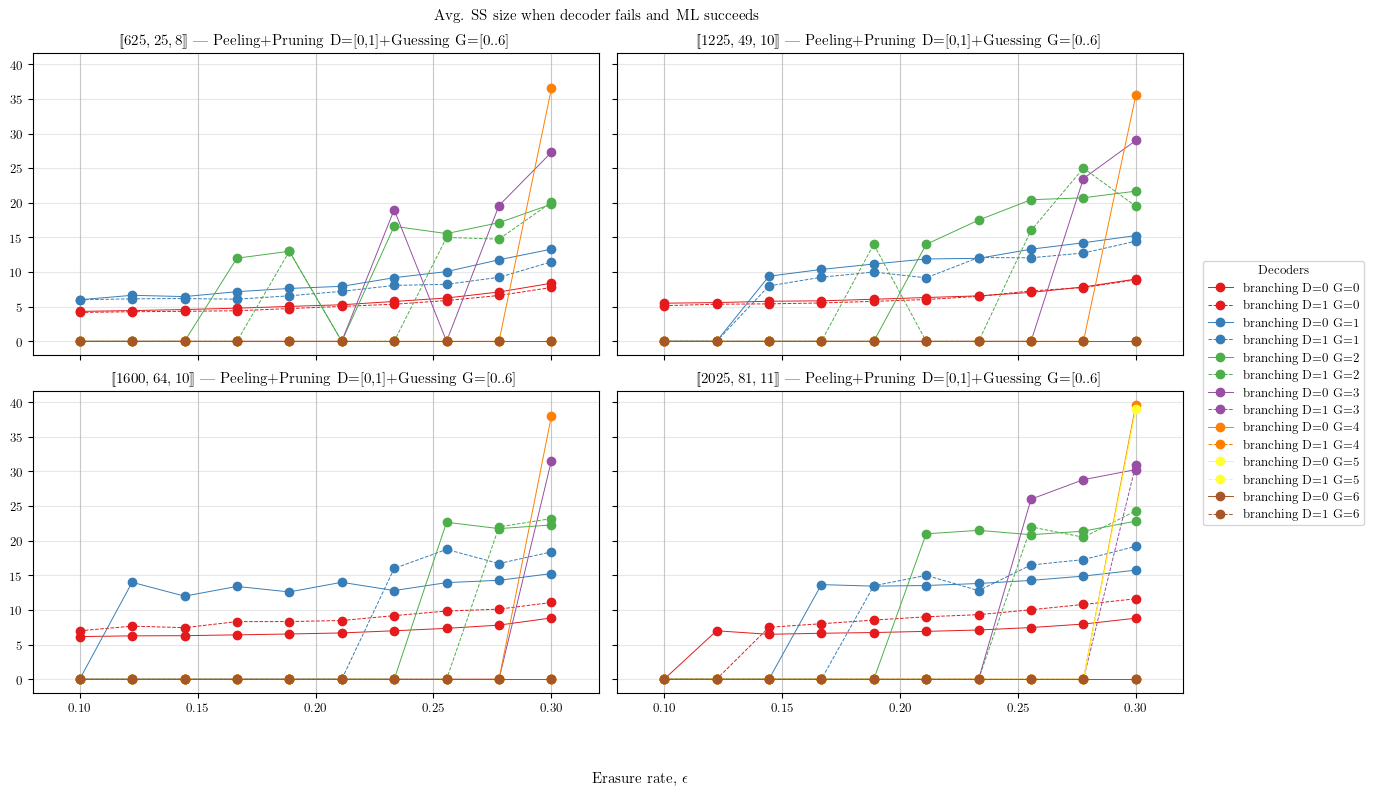

In [6]:
from matplotlib import rc
from matplotlib.ticker import LogLocator

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=9)

fig, axs = plt.subplots(2, 2, figsize=(12,8), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']

plt.suptitle("Avg. SS size when decoder fails and ML succeeds")

er = np.linspace(0.10, 0.30, 10)

codes = sorted(results.keys(), key=lambda x: results[x]["K"])

handles, labels = None, None

for code, ax in zip(codes, axs.flatten()):
    data_dict = results[code]
    ax.set_title(r'$[\!['+f'{data_dict["N"]}, {data_dict["K"]}, {data_dict["D"]}'+r']\!]$'+f' | Peeling+Pruning D=[0,1]+Guessing G=[0..6]')
    
    for g in range(7):
        ax.plot(er, data_dict[f"avgSS_branch_d={0}"][:, g], '-o', label=f"branching D={0} G={g}", linewidth=0.7, color=cmap(g))
        ax.plot(er, data_dict[f"avgSS_branch_d={1}"][:, g], 'o', label=f"branching D={1} G={g}", linewidth=0.7, linestyle='--', color=cmap(g))

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
    
    # ax.set_yscale('log')
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='upper left')

    ax.set_xlim([0.08, 0.32])
    # ax.set_ylim([6, 1000])

fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.0, 0.5), ncol=1, title='Decoders')

plt.tight_layout()
plt.subplots_adjust(bottom=0.125)
# plt.savefig(f'../img/???.pdf')

plt.show()

# Benchmarking P+G on BB codes

In [7]:
import h5py

results = {}
with h5py.File("peeling_guessing_BB_benchmark.hdf5", "r") as f: 
    for code, grp in f.items():
        print(code)
        print(grp.keys())
        print(grp.attrs.keys())
        results[code] = {"ML_ler": np.concatenate([subgrp["ML_ler"][()] for subgrp in grp.values()]), 
                         "ML_eb": np.concatenate([subgrp["ML_eb"][()] for subgrp in grp.values()]), 
                         "N": grp.attrs["N"], "K": grp.attrs["K"],
                        }
        for d in [0, 1]:
            results[code][f"avgSS_branch_d={d}"] = np.stack([subgrp[f"avgSS_branch_d={d}"][()] for subgrp in grp.values()])
            for g in range(7):
                results[code][f'branching_d{d}_g{g}_ler'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_ler'][()] for subgrp in grp.values()])
                results[code][f'branching_d{d}_g{g}_eb'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_eb'][()] for subgrp in grp.values()])
                results[code][f"minSS_branch_d={d}_g={g}"] = grp.attrs[f"minSS_branch_d={d}_g={g}"]
                
        reordering = [int(lbl.split('ER=')[1]) for lbl in grp.keys()]
        results[code]['ML_ler'][reordering] = np.concatenate([subgrp["ML_ler"][()] for subgrp in grp.values()])
        results[code]['ML_eb'][reordering] = np.concatenate([subgrp["ML_eb"][()] for subgrp in grp.values()])
        for d in [0, 1]:
            results[code][f"avgSS_branch_d={d}"][reordering] = np.stack([subgrp[f"avgSS_branch_d={d}"][()] for subgrp in grp.values()])
            for g in range(7):
                results[code][f'branching_d{d}_g{g}_ler'][reordering] = np.concatenate([subgrp[f"branching_d{d}_g{g}_ler"][()] for subgrp in grp.values()])
                results[code][f'branching_d{d}_g{g}_eb'][reordering] = np.concatenate([subgrp[f"branching_d{d}_g{g}_eb"][()] for subgrp in grp.values()])
        
        safe_div = np.vectorize(lambda a,b: a/b if b > 0 else 0)
        print(safe_div(results[code]['ML_eb'], results[code]['ML_eb']))


[[108,8]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_branch_d=1_g=2', 'minSS_branch_d=1_g=3', 'minSS_branch_d=1_g=4', 'minSS_branch_d=1_g=5', 'minSS_branch_d=1_g=6']>
[0 0 0 1 1 1 1 1 1 1 1 1 1 1 1]
[[144,12]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_branch_d=1_g=2', 'minSS_branch_d=1_g=3', 'minSS_branch_

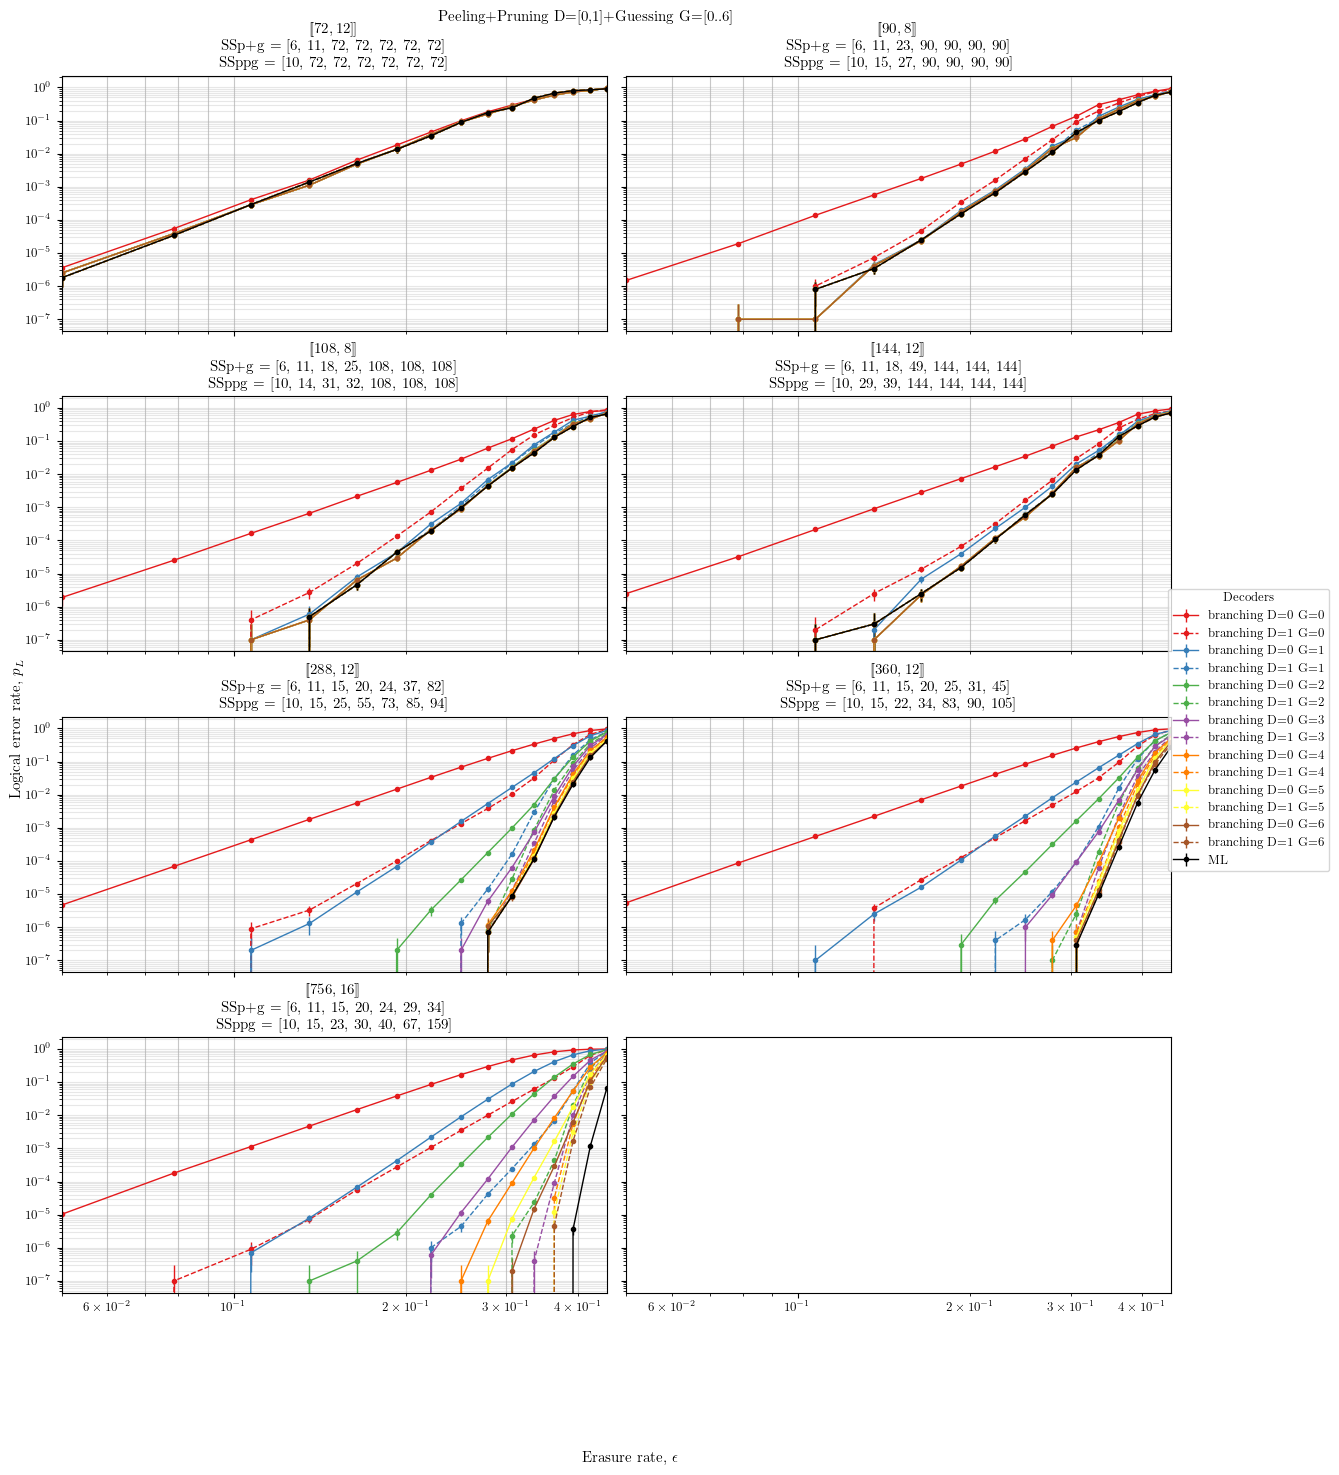

In [8]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=9)


fig, axs = plt.subplots(4, 2, figsize=(12,15), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']

er = np.linspace(0.05, 0.45, 15)

codes = sorted(results.keys(), key=lambda x: results[x]["N"])

handles, labels = None, None

for code, ax in zip(codes, axs.flatten()[:7]):
    data_dict = results[code]
    ax.set_title(r'$[\!['+f'{data_dict["N"]}, {data_dict["K"]}'+r']\!]$' \
                +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    
    for g in range(7):
        ax.errorbar(x=er, y=data_dict[f'branching_d{0}_g{g}_ler'], yerr=data_dict[f'branching_d{0}_g{g}_eb'], 
                    fmt='.-', label=f'branching D={0} G={g}', linewidth=1, color=cmap(g))
        ax.errorbar(x=er, y=data_dict[f'branching_d{1}_g{g}_ler'], yerr=data_dict[f'branching_d{1}_g{g}_eb'], 
                    fmt='.', label=f'branching D={1} G={g}', linewidth=1, linestyle='--', color=cmap(g))
    ax.errorbar(x=er, y=data_dict['ML_ler'], yerr=data_dict['ML_eb'], fmt='.-', label='ML', linewidth=1, color='k')

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

    ax.set_xlim([0.05, 0.45])
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.98, 0.5), ncol=1, title='Decoders')

plt.suptitle(f'Peeling+Pruning D=[0,1]+Guessing G=[0..6]')
plt.tight_layout()
plt.subplots_adjust(bottom=0.125)
# plt.savefig(f'../img/ppg_BB_plots.pdf')

plt.show()

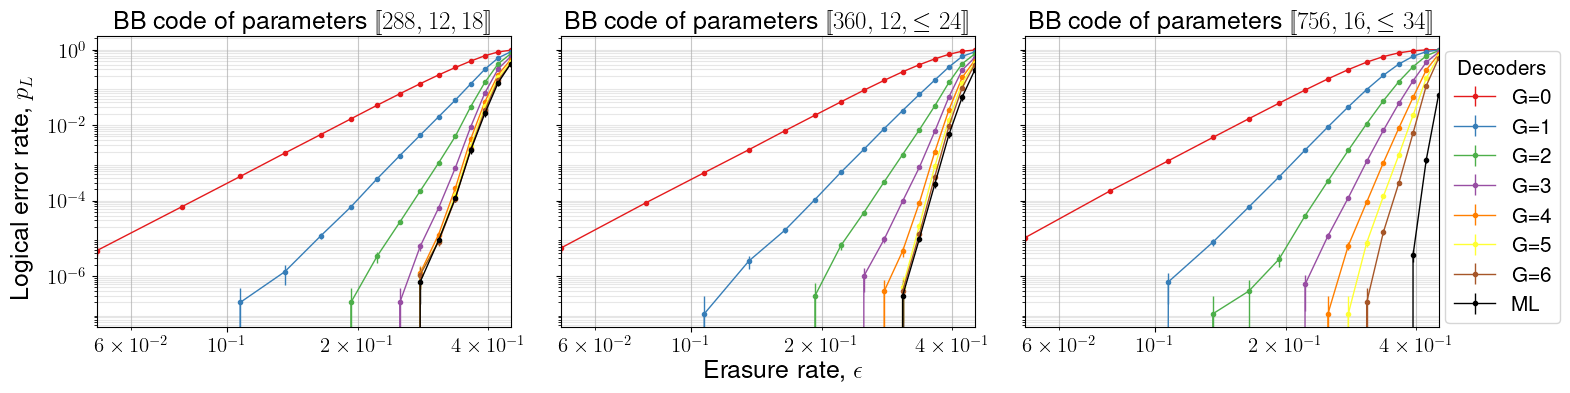

In [9]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
# rc('font', family='serif', size=15)

# Match Beamer’s default font (sans-serif)
rc('font', family='sans-serif', size=15)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Latin Modern Sans', 'Helvetica', 'DejaVu Sans']

# Ensure math text matches LaTeX
rc('mathtext', fontset='cm')  # use Computer Modern for math


fig, axs = plt.subplots(1, 3, figsize=(15,4), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']

er = np.linspace(0.05, 0.45, 15)

# codes = sorted(results.keys(), key=lambda x: results[x]["N"])
codes = ['[[288,12]]', '[[360,12]]', '[[756,16]]']
results[codes[0]]["D"] = 18
results[codes[1]]["Dbound"] = 24
results[codes[2]]["Dbound"] = 34

handles, labels = None, None

for code, ax in zip(codes, axs.flatten()):
    data_dict = results[code]
    ax.set_title(r'BB code of parameters $[\!['+f'{data_dict["N"]}, {data_dict["K"]}, {data_dict["D"] if "D" in data_dict else r'\le'+f'{data_dict["Dbound"]}'}'+r']\!]$') #\
                # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    
    for g in range(7):
        ax.errorbar(x=er, y=data_dict[f'branching_d{0}_g{g}_ler'], yerr=data_dict[f'branching_d{0}_g{g}_eb'], 
                    fmt='.-', label=f'G={g}', linewidth=1, color=cmap(g))
        # ax.errorbar(x=er, y=data_dict[f'branching_d{0}_g{g}_ler'], yerr=data_dict[f'branching_d{0}_g{g}_eb'], 
        #             fmt='.-', label=f'branching D={0} G={g}', linewidth=1, color=cmap(g))
        # ax.errorbar(x=er, y=data_dict[f'branching_d{1}_g{g}_ler'], yerr=data_dict[f'branching_d{1}_g{g}_eb'], 
        #             fmt='.', label=f'branching D={1} G={g}', linewidth=1, linestyle='--', color=cmap(g))
    ax.errorbar(x=er, y=data_dict['ML_ler'], yerr=data_dict['ML_eb'], fmt='.-', label='ML', linewidth=1, color='k')

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

    ax.set_xlim([0.05, 0.45])
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(0.97, 0.5), ncol=1, title='Decoders')

# plt.suptitle(f'Peeling+Pruning D=[0,1]+Guessing G=[0..6]')
plt.tight_layout()
plt.subplots_adjust(bottom=0.15)
# plt.savefig(f'../img/poster_ppg_bb_plots.pdf', bbox_inches='tight')

plt.show()

# Benchmarking P+G on QT codes

In [10]:
import h5py

results = {}
with h5py.File("peeling_guessing_QT_benchmark.hdf5", "r") as f: 
    for code, grp in f.items():
        print(code)
        print(grp.keys())
        print(grp.attrs.keys())
        results[code] = {"ML_ler": np.concatenate([subgrp["ML_ler"][()] for subgrp in grp.values()]), 
                         "ML_eb": np.concatenate([subgrp["ML_eb"][()] for subgrp in grp.values()]), 
                         "N": grp.attrs["N"], "K": grp.attrs["K"],
                        }
        results[code]["D"] = {"[[496,2]]": 32, "[[496,4]]": 30, "[[496,6]]": 26, "[[576,24,22]]": 22, "[[576,24,24]]": 24}[code.split('-')[0]]
        for d in [0]:#, 1]:
            # results[code][f"avgSS_branch_d={d}"] = np.stack([subgrp[f"avgSS_branch_d={d}"][()] for subgrp in grp.values()])
            for g in range(7):
                results[code][f'branching_d{d}_g{g}_ler'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_ler'][()] for subgrp in grp.values()])
                results[code][f'branching_d{d}_g{g}_eb'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_eb'][()] for subgrp in grp.values()])
                results[code][f"minSS_branch_d={d}_g={g}"] = grp.attrs[f"minSS_branch_d={d}_g={g}"]
                
        reordering = [int(lbl.split('ER=')[1]) for lbl in grp.keys()]
        results[code]['ML_ler'][reordering] = np.concatenate([subgrp["ML_ler"][()] for subgrp in grp.values()])
        results[code]['ML_eb'][reordering] = np.concatenate([subgrp["ML_eb"][()] for subgrp in grp.values()])
        for d in [0]:#, 1]:
            # results[code][f"avgSS_branch_d={d}"][reordering] = np.stack([subgrp[f"avgSS_branch_d={d}"][()] for subgrp in grp.values()])
            for g in range(7):
                results[code][f'branching_d{d}_g{g}_ler'][reordering] = np.concatenate([subgrp[f"branching_d{d}_g{g}_ler"][()] for subgrp in grp.values()])
                results[code][f'branching_d{d}_g{g}_eb'][reordering] = np.concatenate([subgrp[f"branching_d{d}_g{g}_eb"][()] for subgrp in grp.values()])
        
        safe_div = np.vectorize(lambda a,b: a/b if b > 0 else 0)
        print(safe_div(results[code]['ML_eb'], results[code]['ML_eb']))


[[496,2]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6']>
[0 0 0 0 0 0 0 0 0 0 0 1 1 1 1]
[[496,2]]-reg
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6']>
[0 0 0 0 0 0 0 0 0 0 0 1 1 1 1]
[[496,4]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_

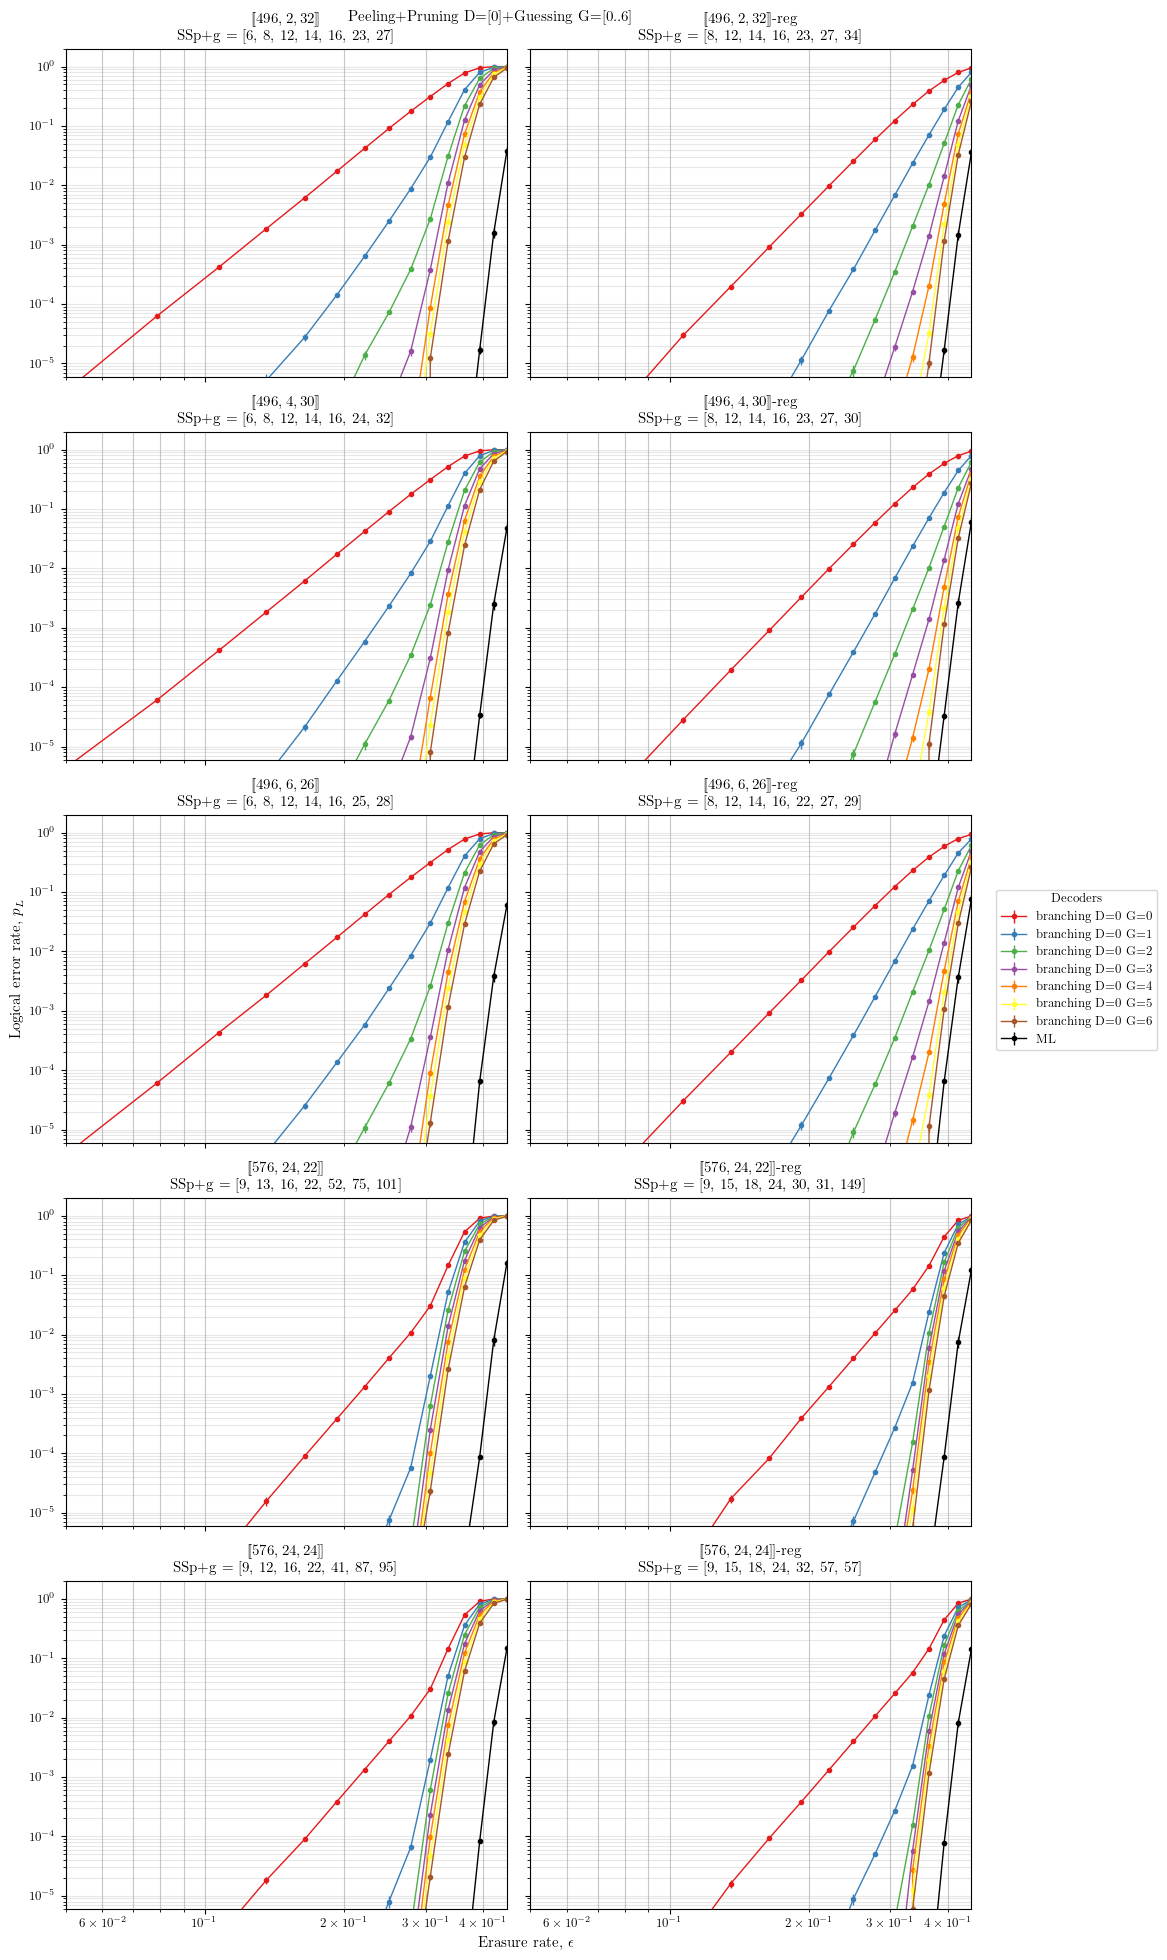

In [11]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=9)


fig, axs = plt.subplots(5, 2, figsize=(10,20), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']

er = np.linspace(0.05, 0.45, 15)

codes = sorted(results.keys(), key=lambda x: results[x]["N"])

handles, labels = None, None

for code, ax in zip(codes, axs.flatten()):
    data_dict = results[code]
    ax.set_title(r'$[\!['+f'{data_dict["N"]}, {data_dict["K"]}, {data_dict["D"]}'+r']\!]$'+f'{'-reg' if 'reg' in code else ''}' \
                +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}')# \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    
    for g in range(7):
        ax.errorbar(x=er, y=data_dict[f'branching_d{0}_g{g}_ler'], yerr=data_dict[f'branching_d{0}_g{g}_eb'], 
                    fmt='.-', label=f'branching D={0} G={g}', linewidth=1, color=cmap(g))
        # ax.errorbar(x=er, y=data_dict[f'branching_d{1}_g{g}_ler'], yerr=data_dict[f'branching_d{1}_g{g}_eb'], 
        #             fmt='.', label=f'branching D={1} G={g}', linewidth=1, linestyle='--', color=cmap(g))
    ax.errorbar(x=er, y=data_dict['ML_ler'], yerr=data_dict['ML_eb'], fmt='.-', label='ML', linewidth=1, color='k')

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

    ax.set_xlim([0.05, 0.45])
    ax.set_ylim([6e-6, 2])
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1, 0.5), ncol=1, title='Decoders')

plt.suptitle(f'Peeling+Pruning D=[0]+Guessing G=[0..6]')
# plt.suptitle(f'Peeling+Pruning D=[0,1]+Guessing G=[0..6]')
plt.tight_layout()
# plt.subplots_adjust(bottom=0.1)
# plt.savefig(f'../img/ppg_QT_plots.pdf')

plt.show()

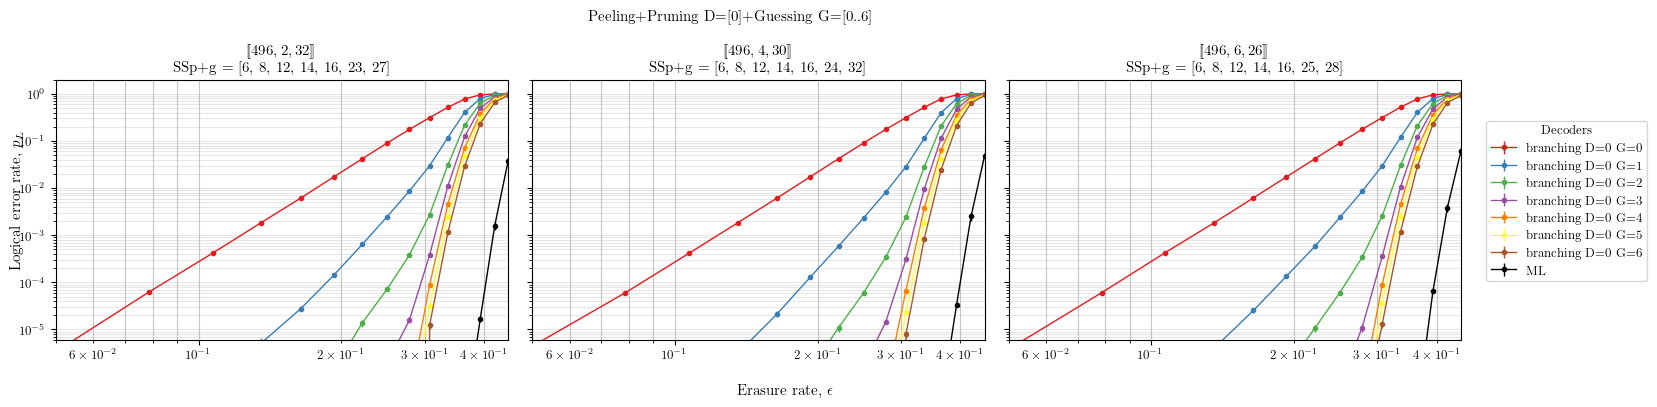

In [12]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=9)


fig, axs = plt.subplots(1, 3, figsize=(15,4), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']

er = np.linspace(0.05, 0.45, 15)

codes = sorted(results.keys(), key=lambda x: results[x]["N"])

handles, labels = None, None

for code, ax in zip(codes[:6:2], axs.flatten()):
    data_dict = results[code]
    ax.set_title(r'$[\!['+f'{data_dict["N"]}, {data_dict["K"]}, {data_dict["D"]}'+r']\!]$'+f'{'-reg' if 'reg' in code else ''}' \
                +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}')# \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    
    for g in range(7):
        ax.errorbar(x=er, y=data_dict[f'branching_d{0}_g{g}_ler'], yerr=data_dict[f'branching_d{0}_g{g}_eb'], 
                    fmt='.-', label=f'branching D={0} G={g}', linewidth=1, color=cmap(g))
        # ax.errorbar(x=er, y=data_dict[f'branching_d{1}_g{g}_ler'], yerr=data_dict[f'branching_d{1}_g{g}_eb'], 
        #             fmt='.', label=f'branching D={1} G={g}', linewidth=1, linestyle='--', color=cmap(g))
    ax.errorbar(x=er, y=data_dict['ML_ler'], yerr=data_dict['ML_eb'], fmt='.-', label='ML', linewidth=1, color='k')

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()

    ax.set_xlim([0.05, 0.45])
    ax.set_ylim([6e-6, 2])
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1, 0.5), ncol=1, title='Decoders')

plt.suptitle(f'Peeling+Pruning D=[0]+Guessing G=[0..6]')
# plt.suptitle(f'Peeling+Pruning D=[0,1]+Guessing G=[0..6]')
plt.tight_layout()
# plt.subplots_adjust(bottom=0.1)
# plt.savefig(f'../img/ppg_QT_plots.pdf')

plt.show()

# Hanwen Yao Cluster decoder

In [13]:
import h5py

families = ['HGP','BB', 'QT']

C_sizes = [0, 10, 20, 100, 200, 400]

er = np.linspace(0.05, 0.45, 15)

func_mean = lambda n_fail, n_total: n_fail/max(1, n_total)
func_std = lambda n_fail, n_total: ((n_fail*(n_total - n_fail)) / (n_total*(n_total - 1)))**.5
func_eb = lambda n_fail, n_total: 1.96*func_std(n_fail, n_total)/np.sqrt(n_total)

results = {fm: {} for fm in families}
for fm in families:
    with h5py.File(f"cluster_peeling_{fm}_benchmark.hdf5", "r") as f: 
        for code, grp in f.items():
            print(code)
            print(grp.keys())
            print(grp.attrs.keys())
            results[fm][code] = {"N": grp.attrs["N"], "K": grp.attrs["K"]}
            
            # Organize data from the available erasure rates
            available_er = {int(lbl.split('ER=')[1]) for lbl in grp}
            
            results[fm][code]['er'] = np.array([er[er_key] for er_key in available_er])
            
            # Cluster decoder results
            for C in C_sizes:
                results[fm][code][f'cluster_C{C}_ler'] = []
                results[fm][code][f'cluster_C{C}_eb'] = []
                
                for er_key in available_er:
                    subgrp = grp[f"ER={er_key}"]
                    
                    cf_sizes, cf_count = subgrp['cluster_failure_sizes'][()], subgrp['cluster_failure_count'][()]
                    cluster_failures_C = sum(n_fails for C_key, n_fails in zip(cf_sizes, cf_count) if C < C_key)
                    num_trials = cf_count.sum()

                    results[fm][code][f'cluster_C{C}_ler'].append(func_mean(cluster_failures_C, num_trials))
                    results[fm][code][f'cluster_C{C}_eb'].append(func_eb(cluster_failures_C, num_trials))

                results[fm][code][f'cluster_C{C}_ler'] = np.array(results[fm][code][f'cluster_C{C}_ler'])
                results[fm][code][f'cluster_C{C}_eb'] = np.array(results[fm][code][f'cluster_C{C}_eb'])

            
            safe_div = np.vectorize(lambda a,b: a/b if b > 0 else 0)
            # print(safe_div(results[code]['ML_eb'], results[code]['ML_eb']))


[1600,64]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N']>
[2025,81]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N']>
[625,25]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N']>
[[288,12]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N']>
[[360,12]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N']>
[[756,16]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER

In [14]:
import h5py

families = ['HGP', 'BB', 'QT']

pgresults = {fm: {} for fm in families}
for fm in families:
    if fm == 'HGP':
        er = np.linspace(0.10, 0.3, 10)
    else:
        er = np.linspace(0.05, 0.45, 15)
    with h5py.File(f"peeling_guessing_{fm}_benchmark.hdf5", "r") as f: 
        for code, grp in f.items():
            if fm == 'HGP':
                code = {
                    '[20,5,8]': '[625,25]', '[28,7,10]': '[1225,65]', '[32,8,10]': '[1600,64]', '[36,9,11]': '[2025,81]',
                }[code]
            print(code)
            print(grp.keys())
            print(grp.attrs.keys())
            pgresults[fm][code] = {"N": grp.attrs["N"], "K": grp.attrs["K"]}
            pgresults[fm][code]['ML_ler'] = np.concatenate([subgrp['ML_ler'][()] for subgrp in grp.values()])
            pgresults[fm][code]['ML_eb'] = np.concatenate([subgrp['ML_eb'][()] for subgrp in grp.values()])
            pgresults[fm][code]['er'] = np.array([er[int(lbl.split('ER=')[1])] for lbl in grp.keys()])

            xye = np.row_stack((pgresults[fm][code]['ML_ler'], pgresults[fm][code]['ML_eb'], pgresults[fm][code]['er']))
            xye = np.row_stack(sorted(xye.T, key=lambda a: a[2])).T
            pgresults[fm][code]['ML_ler'], pgresults[fm][code]['ML_eb'], pgresults[fm][code]['er'] = xye
                
            for g in range(7):
                pgresults[fm][code][f'branching_d{0}_g{g}_ler'] = np.concatenate([subgrp[f'branching_d{0}_g{g}_ler'][()] for subgrp in grp.values()])
                pgresults[fm][code][f'branching_d{0}_g{g}_eb'] = np.concatenate([subgrp[f'branching_d{0}_g{g}_eb'][()] for subgrp in grp.values()])
                pgresults[fm][code][f'er'] = np.array([er[int(lbl.split('ER=')[1])] for lbl in grp.keys()])
                    
                xye = np.row_stack((pgresults[fm][code][f'branching_d{0}_g{g}_ler'], pgresults[fm][code][f'branching_d{0}_g{g}_eb'], pgresults[fm][code][f'er']))
                xye = np.row_stack(sorted(xye.T, key=lambda a: a[2])).T
                pgresults[fm][code][f'branching_d{0}_g{g}_ler'], pgresults[fm][code][f'branching_d{0}_g{g}_eb'], pgresults[fm][code][f'er'] = xye
            
            safe_div = np.vectorize(lambda a,b: a/b if b > 0 else 0)
            # print(safe_div(results[code]['ML_eb'], results[code]['ML_eb']))


[625,25]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['D', 'K', 'N', 'd', 'dt', 'k', 'kt', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_branch_d=1_g=2', 'minSS_branch_d=1_g=3', 'minSS_branch_d=1_g=4', 'minSS_branch_d=1_g=5', 'minSS_branch_d=1_g=6', 'n', 'nt', 's', 'st']>
[1225,65]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['D', 'K', 'N', 'd', 'dt', 'k', 'kt', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_branch_d=1_g=2', 'minSS_branch_d=1_g=3', 'minSS_branch_d=1_g=4', 'minSS_branch_d=1_g=5', 'minSS_branch_

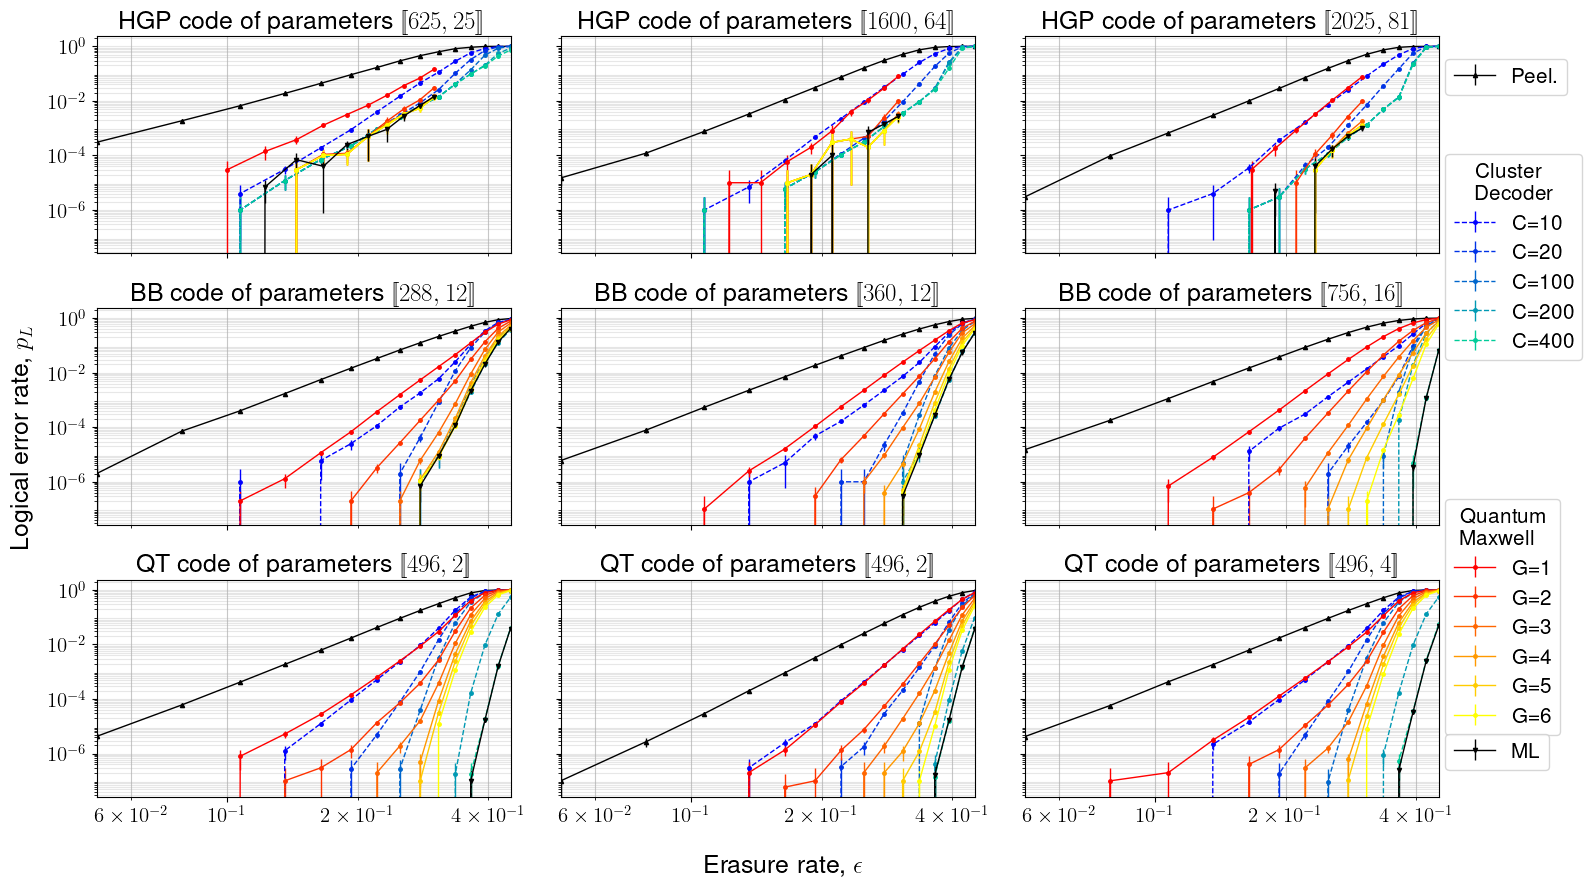

In [15]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=15)

# Match Beamer’s default font (sans-serif)
rc('font', family='sans-serif', size=15)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Latin Modern Sans', 'Helvetica', 'DejaVu Sans']

# Ensure math text matches LaTeX
rc('mathtext', fontset='cm')  # use Computer Modern for math


fig, axs = plt.subplots(3, 3, figsize=(15, 9), sharex=True, sharey=True)
cmap = plt.colormaps['winter']
pgcmap = plt.colormaps['autumn']

handles, labels = None, None
num_C_vals, num_G_vals = len(C_sizes[1:]), 6

for fm, axr in zip(families, axs):
    codes = sorted(results[fm].keys(), key=lambda x: results[fm][x]["N"])
    for code, ax in zip(codes, axr):
        data_dict = results[fm][code]
        pg_data_dict = pgresults[fm][code]

        ax.set_title(f'{fm} '+r'code of parameters $[\!['+f'{data_dict["N"]}, {data_dict["K"]}'+r']\!]$')#+f'{'-reg' if 'reg' in code else ''}' )#\
                    # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                    # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    
        ax.errorbar(x=data_dict[f'er'], y=data_dict[f'cluster_C{0}_ler'], yerr=data_dict[f'cluster_C{0}_eb'], 
                        fmt='^-', label='Peel.', linewidth=1, color='k', markersize=3)
        
        for c, C in enumerate(C_sizes[1:]):
            ax.errorbar(x=data_dict[f'er'], y=data_dict[f'cluster_C{C}_ler'], yerr=data_dict[f'cluster_C{C}_eb'], 
                        fmt='.--', label=f'C={C}', linewidth=1, color=cmap(c/(len(C_sizes)-1)), markersize=5)
        
        for g in range(1, 7):
            ax.errorbar(x=pg_data_dict[f'er'], y=pg_data_dict[f'branching_d0_g{g}_ler'], yerr=pg_data_dict[f'branching_d0_g{g}_eb'], 
                        fmt='.-', label=f'G={g}', linewidth=1, color=pgcmap((g-1)/5), markersize=5)
        
        ax.errorbar(x=pg_data_dict['er'], y=pg_data_dict['ML_ler'], yerr=pg_data_dict['ML_eb'], fmt='v-', label='ML', linewidth=1, color='k', markersize=3)
    
        if handles is None:
            handles, labels = ax.get_legend_handles_labels()
            hpeel, lpeel = [handles[0]], [labels[0]]
            hcluster, lcluster = handles[1:1+num_C_vals], labels[1:1+num_C_vals]
            hqm, lqm = handles[1+num_C_vals:1+num_C_vals+num_G_vals], labels[1+num_C_vals:1+num_C_vals+num_G_vals]
            hml, lml = [handles[-1]], [labels[-1]]
    
        ax.set_xlim([0.05, 0.45])
        # ax.set_ylim([6e-6, 2])
        ax.set_yscale('log')
        ax.set_xscale('log')
        ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
        ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
        ax.grid(which='both', axis='x', alpha=0.7)
        ax.grid(which='both', axis='y', alpha=0.3)
        # ax.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(hpeel, lpeel, loc='center left', bbox_to_anchor=(0.97, 0.65, 0.5, 0.5), ncol=1)
fig.legend(hcluster, lcluster, loc='center left', bbox_to_anchor=(0.97, 0.45, 0.5, 0.5), ncol=1, title='Cluster\nDecoder')
fig.legend(hqm, lqm, loc='center left', bbox_to_anchor=(0.97, 0.05, 0.5, 0.5), ncol=1, title='Quantum\nMaxwell')
fig.legend(hml, lml, loc='center left', bbox_to_anchor=(0.97, -0.1, 0.5, 0.5), ncol=1)

plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
# plt.savefig(f'../img/poster_ppg_qt_plots.pdf', bbox_inches='tight')

plt.show()

## Non-regular vs regular codes

In [16]:
import h5py

families = ['QT']

C_sizes = [10, 20, 50, 100, 200, 400]

er = np.linspace(0.05, 0.45, 15)

func_mean = lambda n_fail, n_total: n_fail/max(1, n_total)
func_std = lambda n_fail, n_total: ((n_fail*(n_total - n_fail)) / (n_total*(n_total - 1)))**.5
func_eb = lambda n_fail, n_total: 1.96*func_std(n_fail, n_total)/np.sqrt(n_total)

results = {fm: {} for fm in families}
for fm in families:
    with h5py.File(f"cluster_peeling_{fm}_benchmark.hdf5", "r") as f: 
        for code, grp in f.items():
            print(code)
            print(grp.keys())
            # print(grp.attrs.keys())
            results[fm][code] = {"N": grp.attrs["N"], "K": grp.attrs["K"]}
            results[fm][code]["D"] = {'[[496,2]]': 32, '[[496,4]]': 30, '[[496,6]]': 26, 
                                      '[[576,24,22]]': 22, '[[576,24,24]]': 24}[code.split('-')[0]]
            print(results[fm][code].keys())
            
            # Organize data from the available erasure rates
            available_er = {int(lbl.split('ER=')[1]) for lbl in grp}
            
            results[fm][code]['er'] = np.array([er[er_key] for er_key in available_er])
            
            # Cluster decoder results
            for C in C_sizes:
                results[fm][code][f'cluster_C{C}_ler'] = []
                results[fm][code][f'cluster_C{C}_eb'] = []
                
                acc_num_trials = ""
                for er_key in available_er:
                    subgrp = grp[f"ER={er_key}"]
                    
                    cf_sizes, cf_count = subgrp['cluster_failure_sizes'][()], subgrp['cluster_failure_count'][()]
                    cluster_failures_C = sum(n_fails for C_key, n_fails in zip(cf_sizes, cf_count) if C < C_key)
                    num_trials = cf_count.sum()

                    results[fm][code][f'cluster_C{C}_ler'].append(func_mean(cluster_failures_C, num_trials))
                    results[fm][code][f'cluster_C{C}_eb'].append(func_eb(cluster_failures_C, num_trials))

                    acc_num_trials += f'ER={er_key}: {num_trials:.0g}, '

                results[fm][code][f'cluster_C{C}_ler'] = np.array(results[fm][code][f'cluster_C{C}_ler'])
                results[fm][code][f'cluster_C{C}_eb'] = np.array(results[fm][code][f'cluster_C{C}_eb'])

            print(acc_num_trials)

            

            # ML results
            results[fm][code]['ML_ler'] = []
            results[fm][code]['ML_eb'] = []
            
            for er_key in available_er:
                subgrp = grp[f"ER={er_key}"]
                
                cf_sizes, cf_count = subgrp['cluster_failure_sizes'][()], subgrp['cluster_failure_count'][()]
                # print(f'{cf_sizes = }')
                # print(f'{cf_count = }')
                ML_failures = sum(n_fails for C_key, n_fails in zip(cf_sizes, cf_count) if results[fm][code]["N"] < C_key)
                num_trials = cf_count.sum()

                results[fm][code]['ML_ler'].append(func_mean(ML_failures, num_trials))
                results[fm][code]['ML_eb'].append(func_eb(ML_failures, num_trials))

            results[fm][code]['ML_ler'] = np.array(results[fm][code]['ML_ler'])
            results[fm][code]['ML_eb'] = np.array(results[fm][code]['ML_eb'])

            # Peeling results
            results[fm][code]['peel_ler'] = []
            results[fm][code]['peel_eb'] = []
            
            for er_key in available_er:
                subgrp = grp[f"ER={er_key}"]
                
                cf_sizes, cf_count = subgrp['cluster_failure_sizes'][()], subgrp['cluster_failure_count'][()]
                peel_failures = sum(n_fails for C_key, n_fails in zip(cf_sizes, cf_count) if 0 < C_key)
                num_trials = cf_count.sum()

                results[fm][code]['peel_ler'].append(func_mean(peel_failures, num_trials))
                results[fm][code]['peel_eb'].append(func_eb(peel_failures, num_trials))

            results[fm][code]['peel_ler'] = np.array(results[fm][code]['peel_ler'])
            results[fm][code]['peel_eb'] = np.array(results[fm][code]['peel_eb'])


            
            # safe_div = np.vectorize(lambda a,b: a/b if b > 0 else 0)
            # print(safe_div(results[code]['ML_eb'], results[code]['ML_eb']))


[[496,2]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
dict_keys(['N', 'K', 'D'])
ER=0: 1e+07, ER=1: 1e+07, ER=2: 1e+07, ER=3: 1e+07, ER=4: 1e+07, ER=5: 1e+07, ER=6: 1e+07, ER=7: 1e+07, ER=8: 1e+07, ER=9: 1e+07, ER=10: 1e+07, ER=11: 1e+07, ER=12: 1e+07, ER=13: 1e+05, ER=14: 1e+04, 
[[496,2]]-reg
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
dict_keys(['N', 'K', 'D'])
ER=0: 1e+07, ER=1: 1e+07, ER=2: 1e+07, ER=3: 1e+07, ER=4: 1e+07, ER=5: 9e+06, ER=6: 9e+06, ER=7: 9e+06, ER=8: 8e+06, ER=9: 8e+06, ER=10: 8e+06, ER=11: 7e+06, ER=12: 7e+06, ER=13: 1e+05, ER=14: 3e+04, 
[[496,4]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
dict_keys(['N', 'K', 'D'])
ER=0: 1e+07, ER=1: 1e+07, ER=2: 1e+07, ER=3: 1e+07, ER=4: 1e

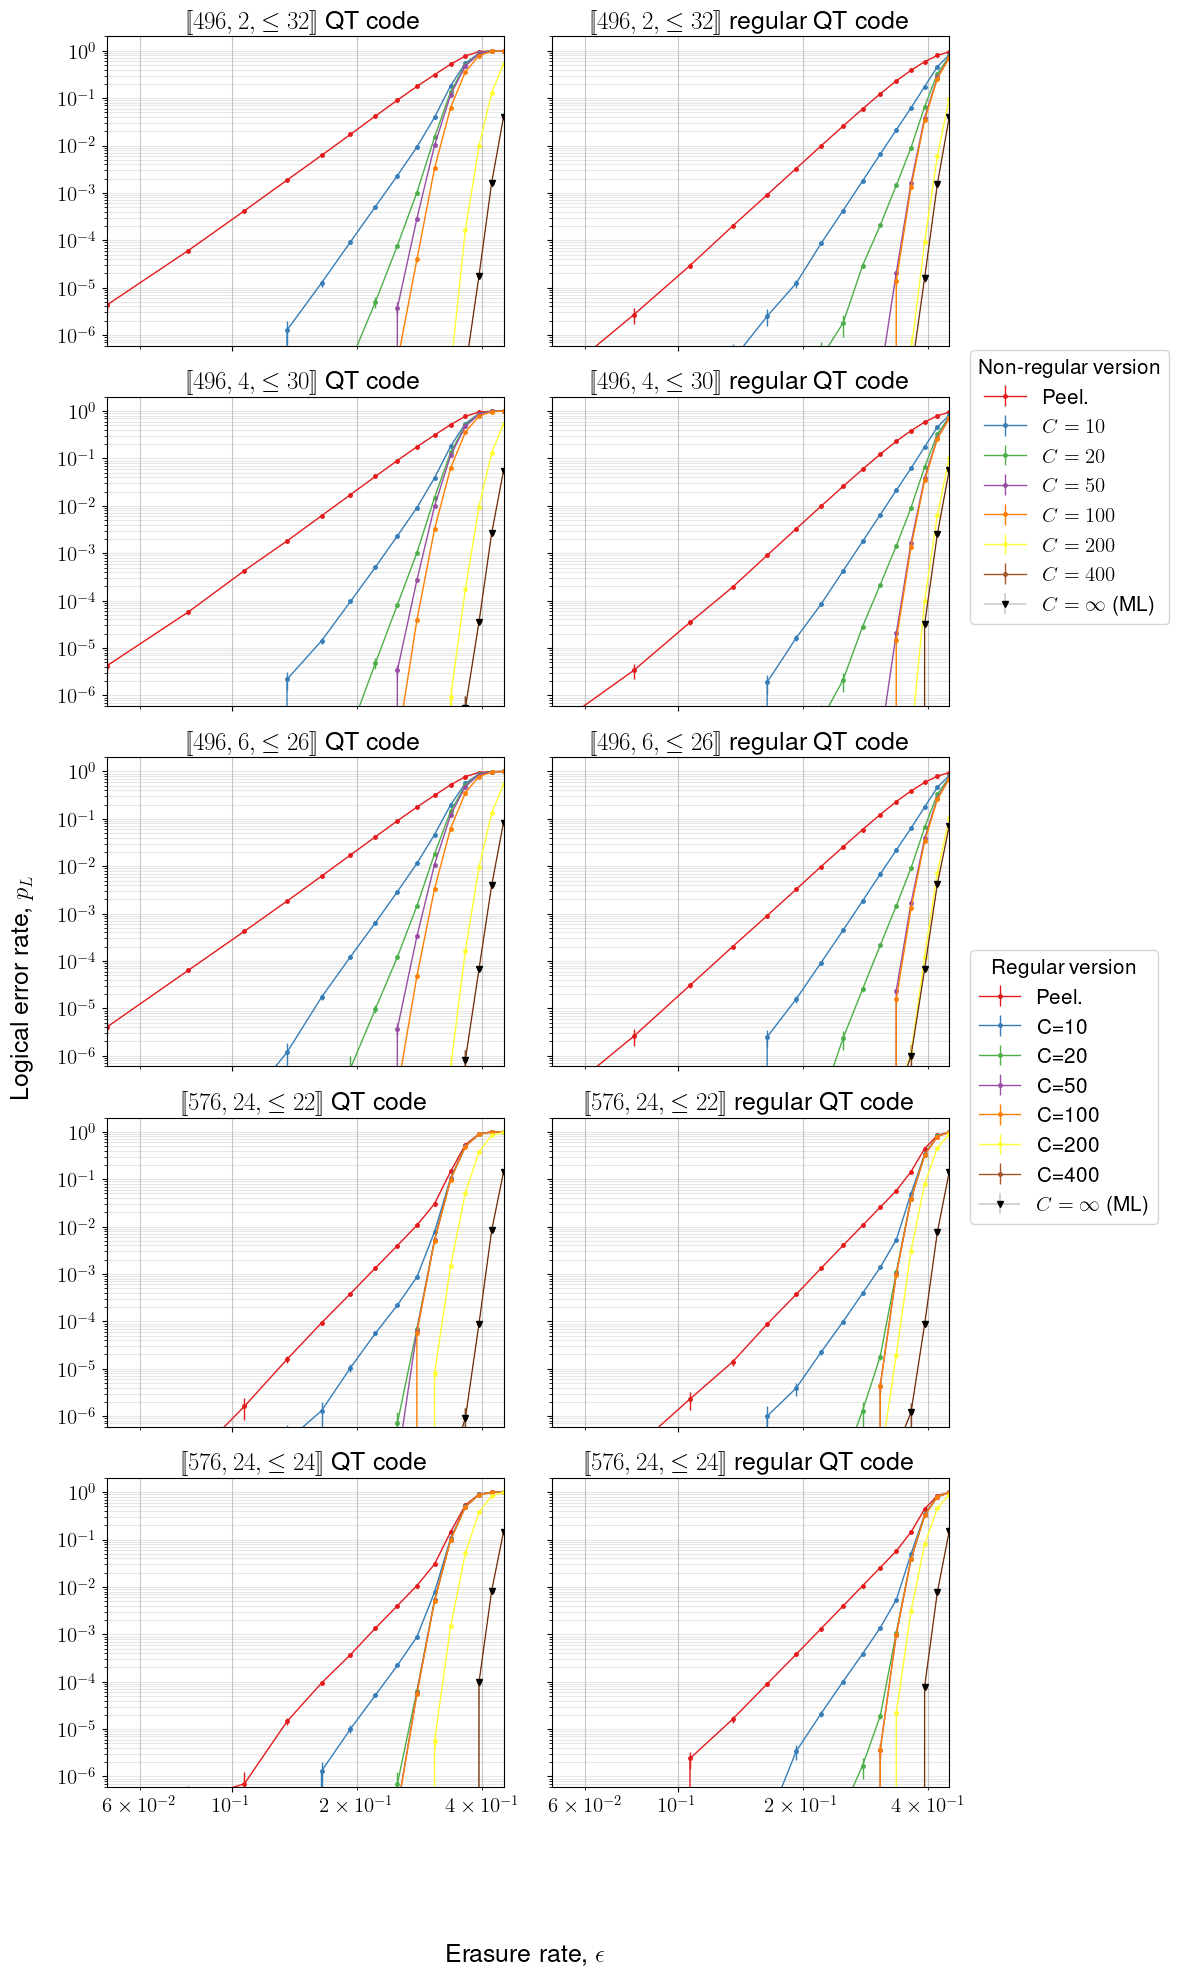

In [17]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=15)

# Match Beamer’s default font (sans-serif)
rc('font', family='sans-serif', size=15)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Latin Modern Sans', 'Helvetica', 'DejaVu Sans']

# Ensure math text matches LaTeX
rc('mathtext', fontset='cm')  # use Computer Modern for math


fig, axs = plt.subplots(5, 2, figsize=(10, 20), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']
# cmap = plt.colormaps['winter']
pgcmap = plt.colormaps['autumn']

handles, labels = None, None
num_C_vals, num_G_vals = len(C_sizes), 6

# for fm, axr in zip(families, axs):
fm = 'QT'
codes = sorted(results[fm].keys(), key=lambda x: results[fm][x]["N"])
for code_nreg, code_reg, (ax, axr) in zip(codes[0::2], codes[1::2], axs):
    data_dict = results[fm][code_nreg]
    data_dict_reg = results[fm][code_reg]
    # pg_data_dict = pgresults[fm][code]

    ax.set_title(r'$[\!['+f'{data_dict["N"]}, {data_dict["K"]}, '+r'\le'+f'{data_dict["D"]}'+r']\!]$'+f' {fm} code')#+f'{'-reg' if 'reg' in code else ''}' )#\
                # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    axr.set_title(r'$[\!['+f'{data_dict["N"]}, {data_dict["K"]}, '+r'\le'+f'{data_dict["D"]}'+r']\!]$'+f' regular {fm} code')#+f'{'-reg' if 'reg' in code else ''}' )#\
                # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')

    ax.errorbar(x=data_dict[f'er'], y=data_dict[f'peel_ler'], yerr=data_dict[f'peel_eb'], 
                    fmt='.-', label='Peel.', linewidth=1, color=cmap(0), markersize=5)
    axr.errorbar(x=data_dict_reg[f'er'], y=data_dict_reg[f'peel_ler'], yerr=data_dict_reg[f'peel_eb'], 
                    fmt='.-', label='Peel.', linewidth=1, color=cmap(0), markersize=5)
    
    for c, C in enumerate(C_sizes):
        ax.errorbar(x=data_dict[f'er'], y=data_dict[f'cluster_C{C}_ler'], yerr=data_dict[f'cluster_C{C}_eb'], 
                    fmt='.-', label=r'$'+f'C={C}'+r'$', linewidth=1, color=cmap(c+1), markersize=5)
        axr.errorbar(x=data_dict_reg[f'er'], y=data_dict_reg[f'cluster_C{C}_ler'], yerr=data_dict_reg[f'cluster_C{C}_eb'], 
                    fmt='.-', label=f'C={C}', linewidth=1, color=cmap(c+1), markersize=5)
    
    # for g in range(1, 7):
    #     ax.errorbar(x=pg_data_dict[f'er'], y=pg_data_dict[f'branching_d0_g{g}_ler'], yerr=pg_data_dict[f'branching_d0_g{g}_eb'], 
    #                 fmt='.-', label=f'G={g}', linewidth=1, color=pgcmap((g-1)/5), markersize=5)
    
    ax.errorbar(x=data_dict['er'], y=data_dict['ML_ler'], yerr=data_dict['ML_eb'], 
                fmt='v-', label=r'$C=\infty$ (ML)', linewidth=0.25, color='k', markersize=5)
    axr.errorbar(x=data_dict_reg['er'], y=data_dict_reg['ML_ler'], yerr=data_dict_reg['ML_eb'], 
                fmt='v-', label=r'$C=\infty$ (ML)', linewidth=0.25, color='k', markersize=5)

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
        rhandles, rlabels = axr.get_legend_handles_labels()
        hnreg, lnreg = handles, labels
        hreg, lreg = rhandles, rlabels
        # hnreg, lnreg = handles[0::2], labels[0::2]
        # hreg, lreg = handles[1::2], labels[1::2]

    ax.set_xlim([0.05, 0.45])
    ax.set_ylim([6e-7, 2])
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
    axr.set_xlim([0.05, 0.45])
    axr.set_ylim([6e-7, 2])
    axr.set_yscale('log')
    axr.set_xscale('log')
    axr.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    axr.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
    axr.grid(which='both', axis='x', alpha=0.7)
    axr.grid(which='both', axis='y', alpha=0.3)
    # axr.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(hnreg, lnreg, loc='center left', bbox_to_anchor=(0.97, 0.50, 0.5, 0.5), ncol=1, title='Non-regular version')
fig.legend(hreg, lreg, loc='center left', bbox_to_anchor=(0.97, 0.20, 0.5, 0.5), ncol=1, title='Regular version')
# fig.legend(hqm, lqm, loc='center left', bbox_to_anchor=(0.97, 0.05, 0.5, 0.5), ncol=1, title='Quantum\nMaxwell')

plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
# plt.savefig(f'../img/poster_ppg_qt_plots.pdf', bbox_inches='tight')

plt.show()

## Quantum Maxwell vs Cluster on regular vs non-regular codes

In [18]:
import h5py

families = ['QT']

pgresults = {fm: {} for fm in families}

for fm in families:
    er = np.linspace(0.05, 0.45, 15)
    with h5py.File(f"peeling_guessing_{fm}_benchmark.hdf5", "r") as f: 
        for code, grp in f.items():
            print(code)
            print(grp.keys())
            print(grp.attrs.keys())
            pgresults[fm][code] = {"N": grp.attrs["N"], "K": grp.attrs["K"]}
            pgresults[fm][code]['ML_ler'] = np.concatenate([subgrp['ML_ler'][()] for subgrp in grp.values()])
            pgresults[fm][code]['ML_eb'] = np.concatenate([subgrp['ML_eb'][()] for subgrp in grp.values()])
            pgresults[fm][code]['er'] = np.array([er[int(lbl.split('ER=')[1])] for lbl in grp.keys()])

            xye = np.row_stack((pgresults[fm][code]['ML_ler'], pgresults[fm][code]['ML_eb'], pgresults[fm][code]['er']))
            xye = np.row_stack(sorted(xye.T, key=lambda a: a[2])).T
            pgresults[fm][code]['ML_ler'], pgresults[fm][code]['ML_eb'], pgresults[fm][code]['er'] = xye
                
            for g in range(7):
                pgresults[fm][code][f'branching_d{0}_g{g}_ler'] = np.concatenate([subgrp[f'branching_d{0}_g{g}_ler'][()] for subgrp in grp.values()])
                pgresults[fm][code][f'branching_d{0}_g{g}_eb'] = np.concatenate([subgrp[f'branching_d{0}_g{g}_eb'][()] for subgrp in grp.values()])
                pgresults[fm][code][f'er'] = np.array([er[int(lbl.split('ER=')[1])] for lbl in grp.keys()])
                    
                xye = np.row_stack((pgresults[fm][code][f'branching_d{0}_g{g}_ler'], pgresults[fm][code][f'branching_d{0}_g{g}_eb'], pgresults[fm][code][f'er']))
                xye = np.row_stack(sorted(xye.T, key=lambda a: a[2])).T
                pgresults[fm][code][f'branching_d{0}_g{g}_ler'], pgresults[fm][code][f'branching_d{0}_g{g}_eb'], pgresults[fm][code][f'er'] = xye
            
            safe_div = np.vectorize(lambda a,b: a/b if b > 0 else 0)
            # print(safe_div(results[code]['ML_eb'], results[code]['ML_eb']))


[[496,2]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6']>
[[496,2]]-reg
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6']>
[[496,4]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_bra

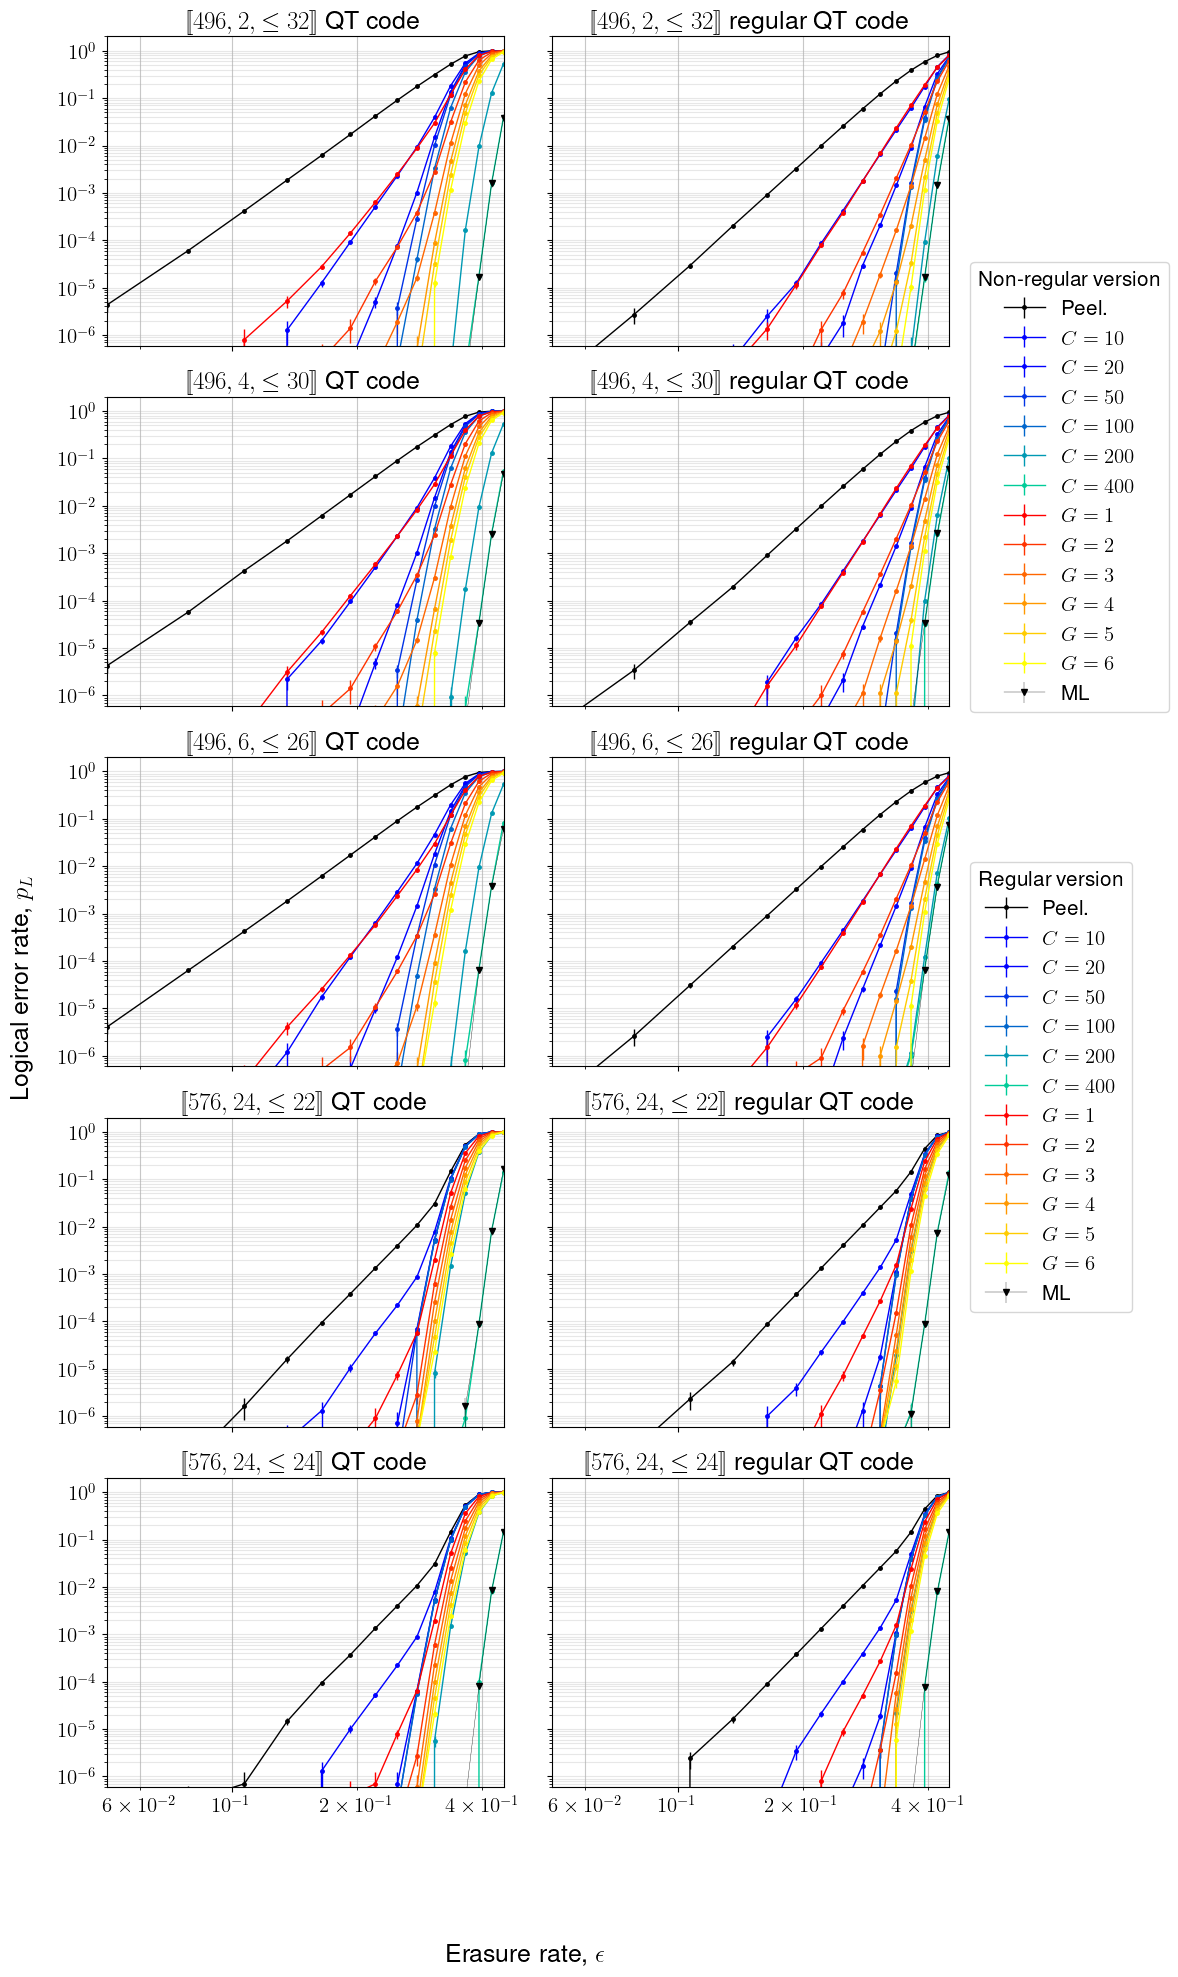

In [19]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=15)

# Match Beamer’s default font (sans-serif)
rc('font', family='sans-serif', size=15)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Latin Modern Sans', 'Helvetica', 'DejaVu Sans']

# Ensure math text matches LaTeX
rc('mathtext', fontset='cm')  # use Computer Modern for math


fig, axs = plt.subplots(5, 2, figsize=(10, 20), sharex=True, sharey=True)
# cmap = plt.colormaps['Set1']
cmap = plt.colormaps['winter']
pgcmap = plt.colormaps['autumn']

handles, labels = None, None
num_C_vals, num_G_vals = len(C_sizes), 6

# for fm, axr in zip(families, axs):
fm = 'QT'
codes = sorted(results[fm].keys(), key=lambda x: results[fm][x]["N"])
for code_nreg, code_reg, (ax, axr) in zip(codes[0::2], codes[1::2], axs):
    data_dict = results[fm][code_nreg]
    data_dict_reg = results[fm][code_reg]
    pg_data_dict = pgresults[fm][code_nreg]
    pg_data_dict_reg = pgresults[fm][code_reg]

    ax.set_title(r'$[\!['+f'{data_dict["N"]}, {data_dict["K"]}, '+r'\le'+f'{data_dict["D"]}'+r']\!]$'+f' {fm} code')#+f'{'-reg' if 'reg' in code else ''}' )#\
                # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    axr.set_title(r'$[\!['+f'{data_dict["N"]}, {data_dict["K"]}, '+r'\le'+f'{data_dict["D"]}'+r']\!]$'+f' regular {fm} code')#+f'{'-reg' if 'reg' in code else ''}' )#\
                # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')

    ax.errorbar(x=data_dict[f'er'], y=data_dict[f'peel_ler'], yerr=data_dict[f'peel_eb'], 
                    fmt='.-', label='Peel.', linewidth=1, color='k', markersize=5)
    axr.errorbar(x=data_dict_reg[f'er'], y=data_dict_reg[f'peel_ler'], yerr=data_dict_reg[f'peel_eb'], 
                    fmt='.-', label='Peel.', linewidth=1, color='k', markersize=5)
    
    for c, C in enumerate(C_sizes):
        ax.errorbar(x=data_dict[f'er'], y=data_dict[f'cluster_C{C}_ler'], yerr=data_dict[f'cluster_C{C}_eb'], 
                    fmt='.-', label=r'$'+f'C={C}'+r'$', linewidth=1, color=cmap((c-1)/(len(C_sizes)-1)), markersize=5)
        axr.errorbar(x=data_dict_reg[f'er'], y=data_dict_reg[f'cluster_C{C}_ler'], yerr=data_dict_reg[f'cluster_C{C}_eb'], 
                    fmt='.-', label=r'$'+f'C={C}'+r'$', linewidth=1, color=cmap((c-1)/(len(C_sizes)-1)), markersize=5)
    
    for g in range(1, 7):
        ax.errorbar(x=pg_data_dict[f'er'], y=pg_data_dict[f'branching_d0_g{g}_ler'], yerr=pg_data_dict[f'branching_d0_g{g}_eb'], 
                    fmt='.-', label=r'$'+f'G={g}'+r'$', linewidth=1, color=pgcmap((g-1)/5), markersize=5)
        axr.errorbar(x=pg_data_dict_reg[f'er'], y=pg_data_dict_reg[f'branching_d0_g{g}_ler'], yerr=pg_data_dict_reg[f'branching_d0_g{g}_eb'], 
                    fmt='.-', label=r'$'+f'G={g}'+r'$', linewidth=1, color=pgcmap((g-1)/5), markersize=5)
    
    ax.errorbar(x=pg_data_dict['er'], y=pg_data_dict['ML_ler'], yerr=pg_data_dict['ML_eb'], 
                fmt='v-', label='ML', linewidth=0.25, color='k', markersize=5)
    axr.errorbar(x=pg_data_dict_reg['er'], y=pg_data_dict_reg['ML_ler'], yerr=pg_data_dict_reg['ML_eb'], 
                fmt='v-', label='ML', linewidth=0.25, color='k', markersize=5)

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
        rhandles, rlabels = axr.get_legend_handles_labels()
        hnreg, lnreg = handles, labels
        hreg, lreg = rhandles, rlabels
        # hnreg, lnreg = handles[0::2], labels[0::2]
        # hreg, lreg = handles[1::2], labels[1::2]

    ax.set_xlim([0.05, 0.45])
    ax.set_ylim([6e-7, 2])
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
    axr.set_xlim([0.05, 0.45])
    axr.set_ylim([6e-7, 2])
    axr.set_yscale('log')
    axr.set_xscale('log')
    axr.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    axr.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
    axr.grid(which='both', axis='x', alpha=0.7)
    axr.grid(which='both', axis='y', alpha=0.3)
    # axr.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(hnreg, lnreg, loc='center left', bbox_to_anchor=(0.97, 0.50, 0.5, 0.5), ncol=1, title='Non-regular version')
fig.legend(hreg, lreg, loc='center left', bbox_to_anchor=(0.97, 0.20, 0.5, 0.5), ncol=1, title='Regular version')
# fig.legend(hqm, lqm, loc='center left', bbox_to_anchor=(0.97, 0.05, 0.5, 0.5), ncol=1, title='Quantum\nMaxwell')

plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
# plt.savefig(f'../img/poster_ppg_qt_plots.pdf', bbox_inches='tight')

plt.show()

# Quantum Maxwell: Pruning vs no-pruning on reg vs non-reg

In [20]:
import h5py

families = ['QT']

pgresults = {fm: {} for fm in families}


for fm in families:
    er = np.linspace(0.05, 0.45, 15)
    with h5py.File(f"peeling_guessing_{fm}_benchmark.hdf5", "r") as f: 
        for code, grp in f.items():
            if "[[576,24,24]]" in code:
                print(code)
                print(grp.keys())
                print(grp.attrs.keys())
                pgresults[fm][code] = {"N": grp.attrs["N"], "K": grp.attrs["K"]}
                pgresults[fm][code]["D"] = {'[[496,2]]': 32, '[[496,4]]': 30, '[[496,6]]': 26, 
                                            '[[576,24,22]]': 22, '[[576,24,24]]': 24}[code.split('-')[0]]
                pgresults[fm][code]['ML_ler'] = np.concatenate([subgrp['ML_ler'][()] for subgrp in grp.values()])
                pgresults[fm][code]['ML_eb'] = np.concatenate([subgrp['ML_eb'][()] for subgrp in grp.values()])
                pgresults[fm][code]['er'] = np.array([er[int(lbl.split('ER=')[1])] for lbl in grp.keys()])
        
                xye = np.row_stack((pgresults[fm][code]['ML_ler'], pgresults[fm][code]['ML_eb'], pgresults[fm][code]['er']))
                xye = np.row_stack(sorted(xye.T, key=lambda a: a[2])).T
                pgresults[fm][code]['ML_ler'], pgresults[fm][code]['ML_eb'], pgresults[fm][code]['er'] = xye
                    
                for d in [0, 1]:
                    for g in range(7):
                        pgresults[fm][code][f'branching_d{d}_g{g}_ler'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_ler'][()] for subgrp in grp.values()])
                        pgresults[fm][code][f'branching_d{d}_g{g}_eb'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_eb'][()] for subgrp in grp.values()])
                        pgresults[fm][code][f'er'] = np.array([er[int(lbl.split('ER=')[1])] for lbl in grp.keys()])
                            
                        xye = np.row_stack((pgresults[fm][code][f'branching_d{d}_g{g}_ler'], pgresults[fm][code][f'branching_d{d}_g{g}_eb'], pgresults[fm][code][f'er']))
                        xye = np.row_stack(sorted(xye.T, key=lambda a: a[2])).T
                        pgresults[fm][code][f'branching_d{d}_g{g}_ler'], pgresults[fm][code][f'branching_d{d}_g{g}_eb'], pgresults[fm][code][f'er'] = xye
                
                safe_div = np.vectorize(lambda a,b: a/b if b > 0 else 0)
                # print(safe_div(results[code]['ML_eb'], results[code]['ML_eb']))


[[576,24,24]]
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_branch_d=1_g=2', 'minSS_branch_d=1_g=3', 'minSS_branch_d=1_g=4', 'minSS_branch_d=1_g=5', 'minSS_branch_d=1_g=6']>
[[576,24,24]]-reg
<KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
<KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_branch_d=1_g=2', 'minSS_branch_d=1_g=3', 'minSS_branch_d=1_g=4', 'minSS_bran

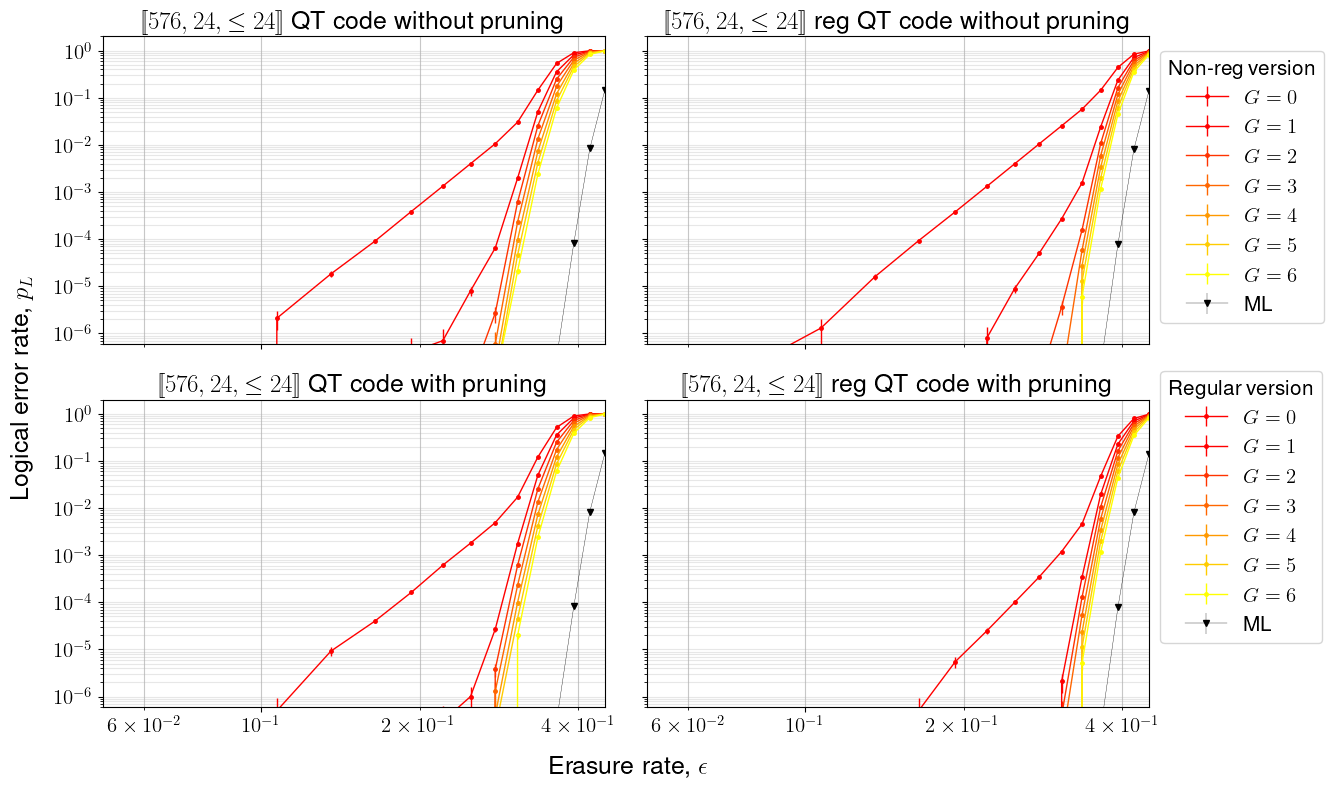

In [21]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=15)

# Match Beamer’s default font (sans-serif)
rc('font', family='sans-serif', size=15)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Latin Modern Sans', 'Helvetica', 'DejaVu Sans']

# Ensure math text matches LaTeX
rc('mathtext', fontset='cm')  # use Computer Modern for math


fig, axs = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']
# cmap = plt.colormaps['winter']
# pgcmap = plt.colormaps['autumn']

handles, labels = None, None
num_C_vals, num_G_vals = len(C_sizes), 6

# for fm, axr in zip(families, axs):
fm = 'QT'
codes = sorted(pgresults[fm].keys(), key=lambda x: results[fm][x]["N"])
for d, ax_row in zip([0, 1], axs):
    # for code_nreg, code_reg, (ax, axr) in zip(codes[0::2], codes[1::2], axs):
    code_nreg, code_reg = codes
    ax, axr = ax_row
    
    pg_data_dict = pgresults[fm][code_nreg]
    pg_data_dict_reg = pgresults[fm][code_reg]

    ax.set_title(r'$[\!['+f'{pg_data_dict["N"]}, {pg_data_dict["K"]}, '+r'\le'+f'{pg_data_dict["D"]}'+r']\!]$'+f' {fm} code {'without' if d==0 else 'with'} pruning')#+f'{'-reg' if 'reg' in code else ''}' )#\
                # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')
    axr.set_title(r'$[\!['+f'{pg_data_dict["N"]}, {pg_data_dict["K"]}, '+r'\le'+f'{pg_data_dict["D"]}'+r']\!]$'+f' reg {fm} code {'without' if d==0 else 'with'} pruning')#+f'{'-reg' if 'reg' in code else ''}' )#\
                # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')

    for g in range(0, 7):
        ax.errorbar(x=pg_data_dict[f'er'], y=pg_data_dict[f'branching_d{d}_g{g}_ler'], yerr=pg_data_dict[f'branching_d{d}_g{g}_eb'], 
                    fmt='.-', label=r'$'+f'G={g}'+r'$', linewidth=1, color=pgcmap((g-1)/5), markersize=5)
        axr.errorbar(x=pg_data_dict_reg[f'er'], y=pg_data_dict_reg[f'branching_d{d}_g{g}_ler'], yerr=pg_data_dict_reg[f'branching_d{d}_g{g}_eb'], 
                    fmt='.-', label=r'$'+f'G={g}'+r'$', linewidth=1, color=pgcmap((g-1)/5), markersize=5)
    
    ax.errorbar(x=pg_data_dict['er'], y=pg_data_dict['ML_ler'], yerr=pg_data_dict['ML_eb'], 
                fmt='v-', label='ML', linewidth=0.25, color='k', markersize=5)
    axr.errorbar(x=pg_data_dict_reg['er'], y=pg_data_dict_reg['ML_ler'], yerr=pg_data_dict_reg['ML_eb'], 
                fmt='v-', label='ML', linewidth=0.25, color='k', markersize=5)

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
        rhandles, rlabels = axr.get_legend_handles_labels()
        hnreg, lnreg = handles, labels
        hreg, lreg = rhandles, rlabels
        # hnreg, lnreg = handles[0::2], labels[0::2]
        # hreg, lreg = handles[1::2], labels[1::2]

    ax.set_xlim([0.05, 0.45])
    ax.set_ylim([6e-7, 2])
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
    axr.set_xlim([0.05, 0.45])
    axr.set_ylim([6e-7, 2])
    axr.set_yscale('log')
    axr.set_xscale('log')
    axr.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    axr.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
    axr.grid(which='both', axis='x', alpha=0.7)
    axr.grid(which='both', axis='y', alpha=0.3)
    # axr.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(hnreg, lnreg, loc='center left', bbox_to_anchor=(0.97, 0.50, 0.5, 0.5), ncol=1, title='Non-reg version')
fig.legend(hreg, lreg, loc='center left', bbox_to_anchor=(0.97, 0.10, 0.5, 0.5), ncol=1, title='Regular version')
# fig.legend(hqm, lqm, loc='center left', bbox_to_anchor=(0.97, 0.05, 0.5, 0.5), ncol=1, title='Quantum\nMaxwell')

plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
# plt.savefig(f'../img/poster_ppg_qt_plots.pdf', bbox_inches='tight')

plt.show()

# Quantum Maxwell guess strategies: random vs score-based

In [22]:
import h5py

families = ['QT']

scresults = {fm: {} for fm in families}
rdresults = {fm: {} for fm in families}

codes = ["[[576,24,24]]"]

for fm in families:
    er = np.linspace(0.05, 0.45, 15)
    with h5py.File(f"peeling_guessing_{fm}_benchmark.hdf5", "r") as f_score, h5py.File(f"peeling_guessing_random_{fm}_benchmark.hdf5", "r") as f_random: 
        for code in codes:
            print(code)
            grp_score = f_score[code]
            grp_random = f_random[code]
            
            print(f'{grp_score.keys() = }')
            print(f'{grp_random.keys() = }')
            print(f'{grp_score.attrs.keys() = }')
            print(f'{grp_random.attrs.keys() = }')
            
            for results, grp in zip([scresults, rdresults], [grp_score, grp_random]):
                results[fm][code] = {"N": grp.attrs["N"], "K": grp.attrs["K"]}
                results[fm][code]["D"] = {'[[496,2]]': 32, '[[496,4]]': 30, '[[496,6]]': 26, 
                                            '[[576,24,22]]': 22, '[[576,24,24]]': 24}[code.split('-')[0]]
                results[fm][code]['ML_ler'] = np.concatenate([subgrp['ML_ler'][()] for subgrp in grp.values()])
                results[fm][code]['ML_eb'] = np.concatenate([subgrp['ML_eb'][()] for subgrp in grp.values()])
                results[fm][code]['er'] = np.array([er[int(lbl.split('ER=')[1])] for lbl in grp.keys()])
        
                xye = np.row_stack((results[fm][code]['ML_ler'], results[fm][code]['ML_eb'], results[fm][code]['er']))
                xye = np.row_stack(sorted(xye.T, key=lambda a: a[2])).T
                results[fm][code]['ML_ler'], results[fm][code]['ML_eb'], results[fm][code]['er'] = xye
                    
                for d in [0, 1]:
                    for g in range(7):
                        results[fm][code][f'branching_d{d}_g{g}_ler'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_ler'][()] for subgrp in grp.values()])
                        results[fm][code][f'branching_d{d}_g{g}_eb'] = np.concatenate([subgrp[f'branching_d{d}_g{g}_eb'][()] for subgrp in grp.values()])
                        results[fm][code][f'er'] = np.array([er[int(lbl.split('ER=')[1])] for lbl in grp.keys()])
                            
                        xye = np.row_stack((results[fm][code][f'branching_d{d}_g{g}_ler'], results[fm][code][f'branching_d{d}_g{g}_eb'], results[fm][code][f'er']))
                        xye = np.row_stack(sorted(xye.T, key=lambda a: a[2])).T
                        results[fm][code][f'branching_d{d}_g{g}_ler'], results[fm][code][f'branching_d{d}_g{g}_eb'], results[fm][code][f'er'] = xye
                
            # safe_div = np.vectorize(lambda a,b: a/b if b > 0 else 0)
            # print(safe_div(results[code]['ML_eb'], results[code]['ML_eb']))


[[576,24,24]]
grp_score.keys() = <KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
grp_random.keys() = <KeysViewHDF5 ['ER=0', 'ER=1', 'ER=10', 'ER=11', 'ER=12', 'ER=13', 'ER=14', 'ER=2', 'ER=3', 'ER=4', 'ER=5', 'ER=6', 'ER=7', 'ER=8', 'ER=9']>
grp_score.attrs.keys() = <KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_branch_d=1_g=2', 'minSS_branch_d=1_g=3', 'minSS_branch_d=1_g=4', 'minSS_branch_d=1_g=5', 'minSS_branch_d=1_g=6']>
grp_random.attrs.keys() = <KeysViewHDF5 ['K', 'N', 'minSS_branch_d=0_g=0', 'minSS_branch_d=0_g=1', 'minSS_branch_d=0_g=2', 'minSS_branch_d=0_g=3', 'minSS_branch_d=0_g=4', 'minSS_branch_d=0_g=5', 'minSS_branch_d=0_g=6', 'minSS_branch_d=1_g=0', 'minSS_branch_d=1_g=1', 'minSS_bran

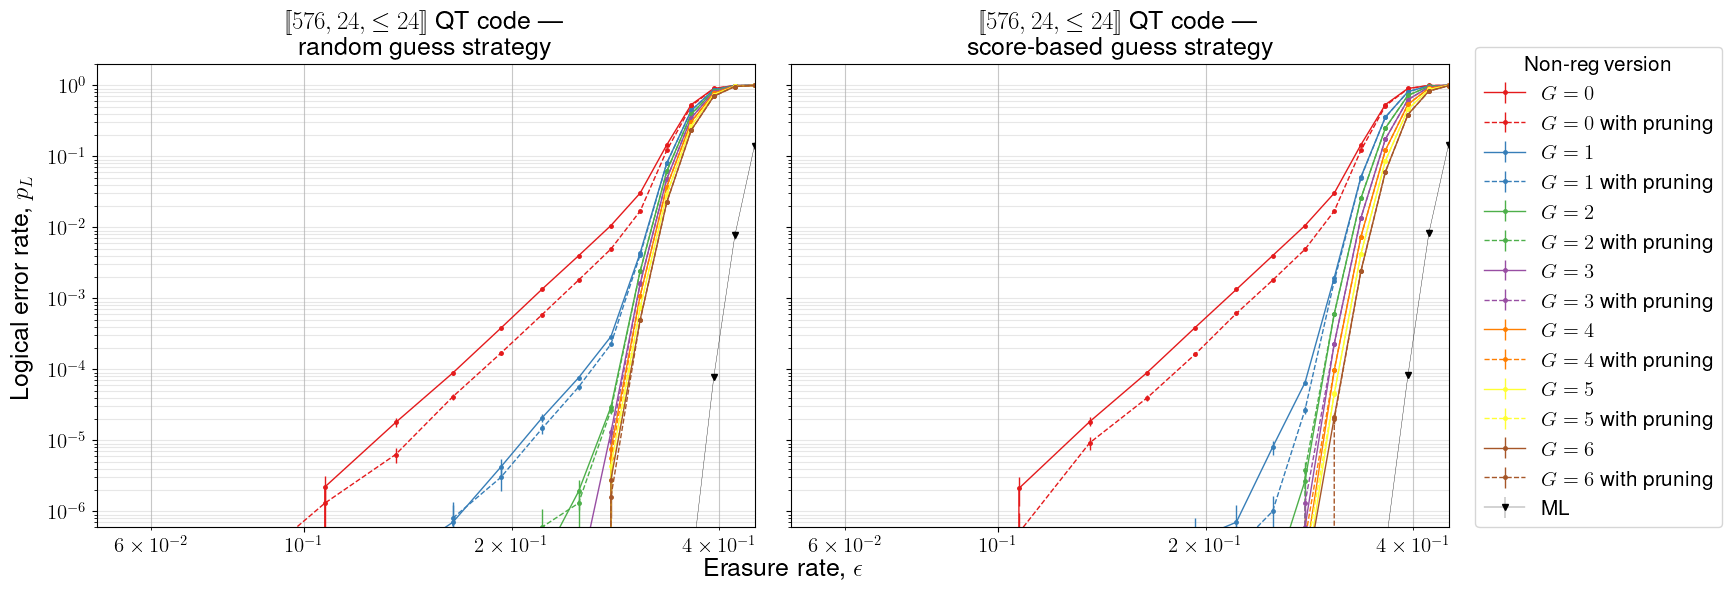

In [23]:
from matplotlib import rc
from matplotlib.ticker import LogLocator
import matplotlib.colors as mcolors

# Use LaTeX for text rendering
rc('text', usetex=True)
rc('font', family='serif', size=15)

# Match Beamer’s default font (sans-serif)
rc('font', family='sans-serif', size=15)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Latin Modern Sans', 'Helvetica', 'DejaVu Sans']

# Ensure math text matches LaTeX
rc('mathtext', fontset='cm')  # use Computer Modern for math


fig, axs = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
cmap = plt.colormaps['Set1']
# cmap = plt.colormaps['winter']
# pgcmap = plt.colormaps['autumn']

handles, labels = None, None
num_C_vals, num_G_vals = len(C_sizes), 6

# for fm, axr in zip(families, axs):
fm = 'QT'
code = "[[576,24,24]]"

for results, ax, strat in zip([rdresults, scresults], axs, ['random', 'score-based']):
    pg_data_dict = results[fm][code]

    ax.set_title(r'$[\!['+f'{pg_data_dict["N"]}, {pg_data_dict["K"]}, '+r'\le'+f'{pg_data_dict["D"]}'+r']\!]$'+f' {fm} code |\n {strat} guess strategy')#+f'{'-reg' if 'reg' in code else ''}' )#\
                # +f'\nSSp+g = {[data_dict[f"minSS_branch_d={0}_g={g}"] for g in range(7)]}' \
                # +f'\nSSppg = {[data_dict[f"minSS_branch_d={1}_g={g}"] for g in range(7)]}')

    for g in range(0, 7):
        ax.errorbar(x=pg_data_dict[f'er'], y=pg_data_dict[f'branching_d{0}_g{g}_ler'], yerr=pg_data_dict[f'branching_d{0}_g{g}_eb'], 
                    fmt='.-', label=r'$'+f'G={g}'+r'$', linewidth=1, color=cmap(g), markersize=5)
        ax.errorbar(x=pg_data_dict[f'er'], y=pg_data_dict[f'branching_d{1}_g{g}_ler'], yerr=pg_data_dict[f'branching_d{1}_g{g}_eb'], 
                    fmt='.--', label=r'$'+f'G={g}'+r'$ with pruning', linewidth=1, color=cmap(g), markersize=5)
    
    ax.errorbar(x=pg_data_dict['er'], y=pg_data_dict['ML_ler'], yerr=pg_data_dict['ML_eb'], 
                fmt='v-', label='ML', linewidth=0.25, color='k', markersize=5)

    if handles is None:
        handles, labels = ax.get_legend_handles_labels()
        hnreg, lnreg = handles, labels
        # hnreg, lnreg = handles[0::2], labels[0::2]
        # hreg, lreg = handles[1::2], labels[1::2]

    ax.set_xlim([0.05, 0.45])
    ax.set_ylim([6e-7, 2])
    ax.set_yscale('log')
    ax.set_xscale('log')
    ax.yaxis.set_minor_locator(LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1, numticks=10)) 
    ax.xaxis.set_minor_locator(LogLocator(base=10.0, subs=[0.06, 0.10, 0.20, 0.40], numticks=10)) 
    ax.grid(which='both', axis='x', alpha=0.7)
    ax.grid(which='both', axis='y', alpha=0.3)
    # ax.legend(loc='lower right')
    
fig.supxlabel(r'Erasure rate, $\epsilon$', x=0.5365)
fig.supylabel(r'Logical error rate, $p_L$')

fig.legend(hnreg, lnreg, loc='center left', bbox_to_anchor=(0.99, 0.25, 0.5, 0.5), ncol=1, title='Non-reg version')
# fig.legend(hqm, lqm, loc='center left', bbox_to_anchor=(0.97, 0.05, 0.5, 0.5), ncol=1, title='Quantum\nMaxwell')

plt.tight_layout()
plt.subplots_adjust(bottom=0.1)
# plt.savefig(f'../img/poster_ppg_qt_plots.pdf', bbox_inches='tight')

plt.show()